# 1次元Euler方程式：6方式とMUSCLの動画比較

数値流束、空間再構築、時間積分の役割を分けて考えながら、同じ問題の時間変化を比較します。計算に必要な関数はこのNotebookに内蔵しています。

| 比較 | 対象 | 固定するもの・変更するもの |
|:--|:--|:--|
| **A：6方式の基本比較** | LF、LW、Roe、LLF (Rusanov)、HLL、HLLC | 同じ問題・格子・CFL規則で、各方式の基本構成を比較 |
| **B：MUSCLの4流束比較** | Roe、LLF (Rusanov)、HLL、HLLC | MUSCL・同じリミッター・SSP-RK2を固定し、数値流束だけを変更 |
| **C：同じ流束の1次・2次精度比較** | 4流束をそれぞれ別の動画にする | 区分一定＋前進Eulerと、MUSCL＋SSP-RK2を比較 |

**AのLWはRichtmyerの2段階・2次精度法、他の5方式は1次精度の構成です。** B・Cの2次精度は滑らかな解での形式的な精度です。リミッターが働く極値や不連続付近では、その次数がそのまま成立するわけではありません。

Bは数値流束の違いを調べる比較です。Cでは空間再構築と時間積分を同時に変えるため、その差をMUSCLだけの効果、または時間積分だけの効果とは断定しません。各要素を独立に調べる方法は、5部構成教材の第IV部（空間再構築）・第V部（時間積分）で扱います。

最初に設定セルを確認し、上から順に実行してください。Aは7問題・14本、B・Cは標準ではエントロピー波・移動接触面・Sodの密度を使う計15本です。B・Cの問題・物理量・流束は`ORDER_CFG`で変更できます。

## 数値計算コア

保存変数、境界条件、数値流束、時間発展、厳密解、診断の関数を定義します。表示用の記録処理は、時間積分に変更を加えません。

In [1]:
from dataclasses import dataclass, replace
from functools import lru_cache
from typing import Optional, Tuple
import time
import numpy as np

In [2]:
class NumericalFailure(RuntimeError):
    """An inadmissible trial state; the integrator retains the last accepted state."""
    def __init__(self, stage, U=None, gamma=1.4, detail=""):
        self.stage = stage
        self.min_rho = np.nan
        self.min_p = np.nan
        self.bad_index = None
        if U is not None:
            rho = np.asarray(U)[..., 0]
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                pressure = (gamma - 1.0) * (U[..., 2] - 0.5 * U[..., 1]**2 / rho)
            self.min_rho = float(np.min(rho))
            self.min_p = float(np.min(pressure))
            bad = (~np.all(np.isfinite(U), axis=-1)) | (~np.isfinite(pressure)) | (rho <= 0.0) | (pressure <= 0.0)
            indices = np.flatnonzero(bad)
            self.bad_index = int(indices[0]) if len(indices) else None
        message = f"{stage}: {detail} min(rho)={self.min_rho:.5e}, min(p)={self.min_p:.5e}"
        super().__init__(message.strip())


def prim_to_cons(W: np.ndarray, gamma: float = 1.4) -> np.ndarray:
    """基本変数 W=(rho,u,p) を保存変数 U=(rho,rho*u,E) に変換する。"""
    W = np.asarray(W, dtype=float)
    rho, u, p = W[..., 0], W[..., 1], W[..., 2]
    if gamma <= 1.0 or np.any(rho <= 0.0) or np.any(p <= 0.0) or not np.all(np.isfinite(W)):
        raise ValueError("gamma > 1, finite rho/u/p, rho > 0 and p > 0 are required.")
    return np.stack((rho, rho * u, p / (gamma - 1.0) + 0.5 * rho * u**2), axis=-1)


def cons_to_prim(U: np.ndarray, gamma: float = 1.4, check: bool = True, stage: str = "state") -> np.ndarray:
    """保存変数から基本変数を求める。非物理的な値を切り上げる操作はしない。"""
    U = np.asarray(U, dtype=float)
    rho = U[..., 0]
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        u = U[..., 1] / rho
        p = (gamma - 1.0) * (U[..., 2] - 0.5 * U[..., 1] * u)
    W = np.stack((rho, u, p), axis=-1)
    if check and (not np.all(np.isfinite(W)) or np.any(rho <= 0.0) or np.any(p <= 0.0)):
        raise NumericalFailure(stage, U, gamma)
    return W


def physical_flux(U: np.ndarray, gamma: float = 1.4, stage: str = "flux state") -> np.ndarray:
    W = cons_to_prim(U, gamma, stage=stage)
    rho, u, p = W[..., 0], W[..., 1], W[..., 2]
    return np.stack((rho * u, rho * u**2 + p, u * (U[..., 2] + p)), axis=-1)


def max_signal_speed(U: np.ndarray, gamma: float = 1.4) -> float:
    W = cons_to_prim(U, gamma)
    return float(np.max(np.abs(W[..., 1]) + np.sqrt(gamma * W[..., 2] / W[..., 0])))

In [3]:
RIEMANN_SOLVERS = ("Roe", "LLF", "HLL", "HLLC")
ALL_SOLVERS = ("LF", "LW", "Roe", "LLF", "HLL", "HLLC")


def roe_averages(UL: np.ndarray, UR: np.ndarray, WL: np.ndarray, WR: np.ndarray, gamma: float):
    rootL, rootR = np.sqrt(WL[..., 0]), np.sqrt(WR[..., 0])
    u = (rootL * WL[..., 1] + rootR * WR[..., 1]) / (rootL + rootR)
    HL, HR = (UL[..., 2] + WL[..., 2]) / WL[..., 0], (UR[..., 2] + WR[..., 2]) / WR[..., 0]
    H = (rootL * HL + rootR * HR) / (rootL + rootR)
    a2 = (gamma - 1.0) * (H - 0.5 * u**2)
    if np.any(a2 <= 0.0) or not np.all(np.isfinite(a2)):
        raise NumericalFailure("Roe average", detail="Nonpositive or nonfinite sound-speed squared.")
    return rootL * rootR, u, H, np.sqrt(a2)


def signal_bounds(UL, UR, WL, WR, gamma: float, method: str = "einfeldt"):
    """HLL/HLLCに同じ外側波速を使う。einfeldtの場合のHLLをHLLEと表示する。"""
    uL, uR = WL[..., 1], WR[..., 1]
    aL, aR = np.sqrt(gamma * WL[..., 2] / WL[..., 0]), np.sqrt(gamma * WR[..., 2] / WR[..., 0])
    if method == "einfeldt":
        _, u, _, a = roe_averages(UL, UR, WL, WR, gamma)
        SL, SR = np.minimum(uL - aL, u - a), np.maximum(uR + aR, u + a)
    elif method == "davis":
        SL, SR = np.minimum(uL - aL, uR - aR), np.maximum(uL + aL, uR + aR)
    elif method == "symmetric":
        amax = np.maximum(np.abs(uL) + aL, np.abs(uR) + aR)
        SL, SR = -amax, amax
    else:
        raise ValueError("Wave speeds must be 'einfeldt', 'davis', or 'symmetric'.")
    return SL, SR


def entropy_abs(lam: np.ndarray, delta: np.ndarray) -> np.ndarray:
    """音響波だけに用いるHarten型の二次正則化。delta=0なら補正なし。"""
    value = np.abs(lam).copy()
    mask = (delta > 0.0) & (value < delta)
    value[mask] = 0.5 * (lam[mask]**2 / delta[mask] + delta[mask])
    return value


def numerical_flux(UL, UR, solver: str, gamma: float = 1.4, dt: Optional[float] = None,
                   dx: Optional[float] = None, wave_speeds: str = "einfeldt", roe_entropy: float = 0.1):
    """各セル境界の数値流束を返す。LLFのalphaは局所的、LFのalphaはdx/dt。"""
    if solver not in ALL_SOLVERS:
        raise ValueError(f"Unknown solver: {solver}")
    UL, UR = np.asarray(UL, dtype=float), np.asarray(UR, dtype=float)
    if UL.ndim != 2 or UL.shape != UR.shape or UL.shape[1] != 3:
        raise ValueError("Interface states must both have shape (number_of_faces, 3).")
    WL, WR = cons_to_prim(UL, gamma, stage="left interface"), cons_to_prim(UR, gamma, stage="right interface")
    FL, FR = physical_flux(UL, gamma), physical_flux(UR, gamma)
    rhoL, uL, pL = WL[..., 0], WL[..., 1], WL[..., 2]
    rhoR, uR, pR = WR[..., 0], WR[..., 1], WR[..., 2]
    aL, aR = np.sqrt(gamma * pL / rhoL), np.sqrt(gamma * pR / rhoR)
    jump = UR - UL
    if solver in ("LF", "LW"):
        if dt is None or dx is None or dt <= 0.0 or dx <= 0.0:
            raise ValueError("LF and LW require positive dt and dx.")
        if solver == "LF":
            return 0.5 * (FL + FR) - 0.5 * (dx / dt) * jump
        Uhalf = 0.5 * (UL + UR) - 0.5 * (dt / dx) * (FR - FL)
        return physical_flux(Uhalf, gamma, stage="LW half-step predictor")
    if solver == "LLF":
        alpha = np.maximum(np.abs(uL) + aL, np.abs(uR) + aR)
        return 0.5 * (FL + FR) - 0.5 * alpha[..., None] * jump
    if solver == "Roe":
        rho, u, H, a = roe_averages(UL, UR, WL, WR, gamma)
        drho, du, dp = rhoR - rhoL, uR - uL, pR - pL
        beta1, beta3 = (dp - rho * a * du) / (2.0 * a**2), (dp + rho * a * du) / (2.0 * a**2)
        beta2 = drho - dp / a**2
        r1 = np.stack((np.ones_like(u), u - a, H - u * a), axis=-1)
        r2 = np.stack((np.ones_like(u), u, 0.5 * u**2), axis=-1)
        r3 = np.stack((np.ones_like(u), u + a, H + u * a), axis=-1)
        delta = roe_entropy * a
        d1, d2, d3 = entropy_abs(u - a, delta), np.abs(u), entropy_abs(u + a, delta)
        dissipation = (beta1 * d1)[..., None] * r1 + (beta2 * d2)[..., None] * r2 + (beta3 * d3)[..., None] * r3
        return 0.5 * (FL + FR - dissipation)
    SL, SR = signal_bounds(UL, UR, WL, WR, gamma, wave_speeds)
    if solver == "HLL":
        Fmiddle = (SR[..., None] * FL - SL[..., None] * FR + (SL * SR)[..., None] * jump) / (SR - SL)[..., None]
        return np.where((SL >= 0.0)[..., None], FL, np.where((SR <= 0.0)[..., None], FR, Fmiddle))
    # HLLC: 音響波の間に接触波 Sstar を復元する。不要な超音速側のstar状態は計算しない。
    result = np.where((SL >= 0.0)[..., None], FL, FR).copy()
    middle = (SL < 0.0) & (SR > 0.0)
    if not np.any(middle):
        return result
    sl, sr = SL[middle], SR[middle]
    rl, rr, vl, vr, pl, pr = rhoL[middle], rhoR[middle], uL[middle], uR[middle], pL[middle], pR[middle]
    numerator = pr - pl + rl * vl * (sl - vl) - rr * vr * (sr - vr)
    denominator = rl * (sl - vl) - rr * (sr - vr)
    if np.any(denominator == 0.0):
        raise NumericalFailure("HLLC contact speed", detail="Zero denominator.")
    sm = numerator / denominator
    if np.any(sl >= sm) or np.any(sm >= sr):
        raise NumericalFailure("HLLC wave ordering", detail="Expected SL < Sstar < SR.")
    rsl, rsr = rl * (sl - vl) / (sl - sm), rr * (sr - vr) / (sr - sm)
    esl = rsl * (UL[middle, 2] / rl + (sm - vl) * (sm + pl / (rl * (sl - vl))))
    esr = rsr * (UR[middle, 2] / rr + (sm - vr) * (sm + pr / (rr * (sr - vr))))
    Usl, Usr = np.column_stack((rsl, rsl * sm, esl)), np.column_stack((rsr, rsr * sm, esr))
    Fsl, Fsr = FL[middle] + sl[:, None] * (Usl - UL[middle]), FR[middle] + sr[:, None] * (Usr - UR[middle])
    result[middle] = np.where((sm >= 0.0)[:, None], Fsl, Fsr)
    return result

In [4]:
@dataclass(frozen=True)
class Problem:
    key: str
    title: str
    bounds: Tuple[float, float]
    final_time: float
    boundary: str
    left: Optional[Tuple[float, float, float]] = None
    right: Optional[Tuple[float, float, float]] = None
    x0: float = 0.5
    velocity: float = 1.0


PROBLEMS = {
    "entropy": Problem("entropy", "Smooth entropy-wave advection", (0.0, 1.0), 1.0, "periodic"),
    "contact": Problem("contact", "Moving contact discontinuities", (0.0, 1.0), 0.25, "periodic"),
    "contact_static": Problem("contact_static", "Stationary contact discontinuities", (0.0, 1.0), 0.25, "periodic", velocity=0.0),
    "sod": Problem("sod", "Sod shock tube", (0.0, 1.0), 0.2, "outflow", (1.0, 0.0, 1.0), (0.125, 0.0, 0.1)),
    "double_rarefaction": Problem("double_rarefaction", "Two strong rarefactions", (-0.5, 0.5), 0.15, "outflow", (1.0, -2.0, 0.4), (1.0, 2.0, 0.4), x0=0.0),
    "lax": Problem("lax", "Lax shock tube", (-0.5, 0.5), 0.14, "outflow", (0.445, 0.698, 3.528), (0.5, 0.0, 0.571), x0=0.0),
    "transonic": Problem("transonic", "Transonic rarefaction", (0.0, 1.0), 0.2, "outflow", (1.0, 0.75, 1.0), (0.125, 0.0, 0.1), x0=0.3),
    "shu_osher": Problem("shu_osher", "Shu-Osher shock / entropy-wave interaction", (-5.0, 5.0), 1.8, "inflow_outflow", (27.0 / 7.0, 20.0 * np.sqrt(1.4) / 9.0, 31.0 / 3.0), x0=-4.0),
}


def grid_for(problem: Problem, n: int):
    if not isinstance(n, (int, np.integer)) or n < 8:
        raise ValueError("n must be an integer >= 8.")
    edges = np.linspace(problem.bounds[0], problem.bounds[1], n + 1)
    return edges, 0.5 * (edges[:-1] + edges[1:]), float(edges[1] - edges[0])


def advected_cell_average(problem: Problem, edges: np.ndarray, t: float, gamma: float):
    """正弦波/矩形波の厳密なセル平均。密度だけでなく保存変数を平均する。"""
    dx, x = np.diff(edges), 0.5 * (edges[:-1] + edges[1:])
    v, length = problem.velocity, problem.bounds[1] - problem.bounds[0]
    if problem.key == "entropy":
        rho = 1.0 + 0.2 * np.sinc(dx / length) * np.sin(2.0 * np.pi * (x - v * t) / length)
    else:
        shift = (v * t) % length
        a, b = 0.25 + shift, 0.45 + shift
        overlap = np.zeros_like(x)
        for k in (-1, 0, 1):
            overlap += np.maximum(0.0, np.minimum(edges[1:], b + k * length) - np.maximum(edges[:-1], a + k * length))
        rho = 1.0 + overlap / dx
    W = np.column_stack((rho, np.full_like(rho, v), np.ones_like(rho)))
    return prim_to_cons(W, gamma)


def initial_cell_average(problem: Problem, edges: np.ndarray, gamma: float = 1.4) -> np.ndarray:
    if problem.key in ("entropy", "contact", "contact_static"):
        return advected_cell_average(problem, edges, 0.0, gamma)
    dx = np.diff(edges)
    frac = np.clip((problem.x0 - edges[:-1]) / dx, 0.0, 1.0)
    UL = prim_to_cons(np.array(problem.left), gamma)
    if problem.key != "shu_osher":
        UR = prim_to_cons(np.array(problem.right), gamma)
        return frac[:, None] * UL + (1.0 - frac)[:, None] * UR
    # 正弦波部分の密度を解析積分する。波と初期衝撃波が同じセルにあってもよい。
    lo, hi = np.maximum(edges[:-1], problem.x0), edges[1:]
    active = hi > lo
    integral_rho = np.zeros_like(dx)
    integral_rho[active] = (hi[active] - lo[active]) + 0.04 * (np.cos(5.0 * lo[active]) - np.cos(5.0 * hi[active]))
    U = frac[:, None] * UL
    U[:, 0] += integral_rho / dx
    U[:, 2] += (1.0 - frac) / (gamma - 1.0)
    return U

In [5]:
@lru_cache(maxsize=128)
def riemann_structure(left: tuple, right: tuple, gamma: float = 1.4):
    """理想気体の厳密リーマン解。真空を含まない問題を対象にpressureを二分法で解く。"""
    rL, uL, pL = left
    rR, uR, pR = right
    if min(rL, rR, pL, pR) <= 0.0 or gamma <= 1.0:
        raise ValueError("Exact solver requires positive input states and gamma > 1.")
    cL, cR = np.sqrt(gamma * pL / rL), np.sqrt(gamma * pR / rR)
    if uR - uL >= 2.0 * (cL + cR) / (gamma - 1.0):
        raise ValueError("This exact solver does not implement a physical vacuum.")

    def wave_function(p, rho, pk, ck):
        if p > pk:
            return (p - pk) * np.sqrt((2.0 / ((gamma + 1.0) * rho)) / (p + (gamma - 1.0) * pk / (gamma + 1.0)))
        return (2.0 * ck / (gamma - 1.0)) * ((p / pk)**((gamma - 1.0) / (2.0 * gamma)) - 1.0)

    def residual(p):
        return wave_function(p, rL, pL, cL) + wave_function(p, rR, pR, cR) + uR - uL

    lower, upper = 0.0, max(pL, pR)
    for _ in range(100):
        if residual(upper) >= 0.0:
            break
        upper *= 2.0
    else:
        raise RuntimeError("Cannot bracket the star pressure.")
    for _ in range(180):
        p = 0.5 * (lower + upper)
        if residual(p) > 0.0:
            upper = p
        else:
            lower = p
        if upper - lower <= 2.0e-13 * max(upper, 1.0e-300):
            break
    ps = 0.5 * (lower + upper)
    us = 0.5 * (uL + uR + wave_function(ps, rR, pR, cR) - wave_function(ps, rL, pL, cL))
    b = (gamma - 1.0) / (gamma + 1.0)
    rLs = rL * ((ps / pL + b) / (b * ps / pL + 1.0) if ps > pL else (ps / pL)**(1.0 / gamma))
    rRs = rR * ((ps / pR + b) / (b * ps / pR + 1.0) if ps > pR else (ps / pR)**(1.0 / gamma))
    if ps > pL:
        sl = uL - cL * np.sqrt((gamma + 1.0) * ps / (2.0 * gamma * pL) + (gamma - 1.0) / (2.0 * gamma))
        left_speeds = (sl, sl)
    else:
        left_speeds = (uL - cL, us - cL * (ps / pL)**((gamma - 1.0) / (2.0 * gamma)))
    if ps > pR:
        sr = uR + cR * np.sqrt((gamma + 1.0) * ps / (2.0 * gamma * pR) + (gamma - 1.0) / (2.0 * gamma))
        right_speeds = (sr, sr)
    else:
        right_speeds = (us + cR * (ps / pR)**((gamma - 1.0) / (2.0 * gamma)), uR + cR)
    return {"pstar": ps, "ustar": us, "rhoLstar": rLs, "rhoRstar": rRs, "left_speeds": left_speeds, "right_speeds": right_speeds, "residual": residual(ps)}


def riemann_primitive(x: np.ndarray, t: float, problem: Problem, gamma: float = 1.4):
    original_shape = np.asarray(x).shape
    x = np.asarray(x, dtype=float).ravel()
    left, right = np.array(problem.left), np.array(problem.right)
    if t <= 0.0:
        return np.where((x < problem.x0)[:, None], left, right).reshape(original_shape + (3,))
    data = riemann_structure(tuple(problem.left), tuple(problem.right), gamma)
    ps, us = data["pstar"], data["ustar"]
    rL, uL, pL = left
    rR, uR, pR = right
    cL, cR = np.sqrt(gamma * pL / rL), np.sqrt(gamma * pR / rR)
    xi = (x - problem.x0) / t
    is_left = xi <= us
    W = np.where(is_left[:, None], np.array((data["rhoLstar"], us, ps)), np.array((data["rhoRstar"], us, ps)))
    lh, lt = data["left_speeds"]
    rt, rh = data["right_speeds"]
    W[xi < lh] = left
    W[xi > rh] = right
    if ps <= pL:
        fan = is_left & (xi >= lh) & (xi <= lt)
        c = (2.0 / (gamma + 1.0)) * (cL + 0.5 * (gamma - 1.0) * (uL - xi[fan]))
        W[fan, 0] = rL * (c / cL)**(2.0 / (gamma - 1.0))
        W[fan, 1] = (2.0 / (gamma + 1.0)) * (cL + 0.5 * (gamma - 1.0) * uL + xi[fan])
        W[fan, 2] = pL * (c / cL)**(2.0 * gamma / (gamma - 1.0))
    if ps <= pR:
        fan = (~is_left) & (xi >= rt) & (xi <= rh)
        c = (2.0 / (gamma + 1.0)) * (cR - 0.5 * (gamma - 1.0) * (uR - xi[fan]))
        W[fan, 0] = rR * (c / cR)**(2.0 / (gamma - 1.0))
        W[fan, 1] = (2.0 / (gamma + 1.0)) * (-cR + 0.5 * (gamma - 1.0) * uR + xi[fan])
        W[fan, 2] = pR * (c / cR)**(2.0 * gamma / (gamma - 1.0))
    return W.reshape(original_shape + (3,))


def exact_pointwise(problem: Problem, x: np.ndarray, t: float, gamma: float = 1.4):
    x = np.asarray(x, dtype=float)
    if problem.key == "shu_osher":
        raise ValueError("No exact solution is supplied for Shu-Osher.")
    if problem.key in ("entropy", "contact", "contact_static"):
        coordinate = (x - problem.velocity * t) % 1.0
        rho = 1.0 + 0.2 * np.sin(2.0 * np.pi * coordinate) if problem.key == "entropy" else 1.0 + ((coordinate >= 0.25) & (coordinate < 0.45))
        return np.stack((rho, np.full_like(x, problem.velocity), np.ones_like(x)), axis=-1)
    return riemann_primitive(x, t, problem, gamma)


def exact_cell_average(problem: Problem, edges: np.ndarray, t: float, gamma: float = 1.4, nq: int = 12):
    """リーマン解は波面で区間を分割したGauss積分。保存変数のセル平均を返す。"""
    if problem.key in ("entropy", "contact", "contact_static"):
        return advected_cell_average(problem, edges, t, gamma)
    if problem.key == "shu_osher":
        raise ValueError("Use a numerical reference for Shu-Osher.")
    if t <= 0.0:
        return initial_cell_average(problem, edges, gamma)
    data = riemann_structure(tuple(problem.left), tuple(problem.right), gamma)
    speeds = np.array(data["left_speeds"] + (data["ustar"],) + data["right_speeds"])
    fronts = problem.x0 + t * speeds
    partitions = np.unique(np.r_[edges, fronts[(fronts > edges[0]) & (fronts < edges[-1])]])
    lo, hi = partitions[:-1], partitions[1:]
    nodes, weights = np.polynomial.legendre.leggauss(nq)
    points = 0.5 * (lo + hi)[:, None] + 0.5 * (hi - lo)[:, None] * nodes
    states = prim_to_cons(riemann_primitive(points, t, problem, gamma), gamma)
    integrals = 0.5 * (hi - lo)[:, None] * np.einsum("q,sqk->sk", weights, states)
    owners = np.searchsorted(edges, 0.5 * (lo + hi), side="right") - 1
    averaged = np.zeros((len(edges) - 1, 3))
    np.add.at(averaged, owners, integrals)
    return averaged / np.diff(edges)[:, None]

In [6]:
def minmod(a: np.ndarray, b: np.ndarray):
    same_sign = np.sign(a) == np.sign(b)
    return np.where(same_sign, np.sign(a) * np.minimum(np.abs(a), np.abs(b)), 0.0)


def ghost_cells(U: np.ndarray, problem: Problem, gamma: float):
    """左右2個ずつのゴーストセルを作る。境界条件は各RK段階で更新する。"""
    if problem.boundary == "periodic":
        return np.concatenate((U[-2:], U, U[:2]), axis=0)
    if problem.boundary == "outflow":
        return np.concatenate((np.repeat(U[:1], 2, axis=0), U, np.repeat(U[-1:], 2, axis=0)), axis=0)
    if problem.boundary == "inflow_outflow":
        UL = prim_to_cons(np.array(problem.left), gamma)
        return np.concatenate((np.repeat(UL[None, :], 2, axis=0), U, np.repeat(U[-1:], 2, axis=0)), axis=0)
    raise ValueError(f"Unknown boundary condition: {problem.boundary}")


def interface_states(U: np.ndarray, problem: Problem, gamma: float, order: int, limiter: str):
    Ug = ghost_cells(U, problem, gamma)
    if order == 1:
        return Ug[1:-2].copy(), Ug[2:-1].copy()
    Wg = cons_to_prim(Ug, gamma, stage="MUSCL cell state")
    dm, dp = Wg[1:-1] - Wg[:-2], Wg[2:] - Wg[1:-1]
    slopes = np.zeros_like(Wg)
    if limiter == "minmod":
        slopes[1:-1] = minmod(dm, dp)
    elif limiter == "mc":
        slopes[1:-1] = minmod(0.5 * (dm + dp), minmod(2.0 * dm, 2.0 * dp))
    elif limiter == "unlimited":
        slopes[1:-1] = 0.5 * (dm + dp)
    else:
        raise ValueError("limiter must be 'minmod', 'mc', or 'unlimited'.")
    WL, WR = Wg[1:-2] + 0.5 * slopes[1:-2], Wg[2:-1] - 0.5 * slopes[2:-1]
    for state in (WL, WR):
        if not np.all(np.isfinite(state)) or np.any(state[:, 0] <= 0.0) or np.any(state[:, 2] <= 0.0):
            raise NumericalFailure("MUSCL reconstruction", detail="A reconstructed rho or p is not positive.")
    return prim_to_cons(WL, gamma), prim_to_cons(WR, gamma)


def advance(U, problem: Problem, solver: str, dt: float, dx: float, gamma: float,
            order: int, limiter: str, wave_speeds: str, roe_entropy: float):
    """更新後の保存変数と、同じ数値流束で積算した領域への正味流入量を返す。"""
    UL, UR = interface_states(U, problem, gamma, order, limiter)
    F1 = numerical_flux(UL, UR, solver, gamma, dt, dx, wave_speeds, roe_entropy)
    U1 = U - (dt / dx) * (F1[1:] - F1[:-1])
    cons_to_prim(U1, gamma, stage="RK stage 1" if order == 2 else "full-step update")
    if order == 1:
        return U1, dt * (F1[0] - F1[-1])
    UL, UR = interface_states(U1, problem, gamma, order, limiter)
    F2 = numerical_flux(UL, UR, solver, gamma, dt, dx, wave_speeds, roe_entropy)
    Unew = 0.5 * U + 0.5 * (U1 - (dt / dx) * (F2[1:] - F2[:-1]))
    cons_to_prim(Unew, gamma, stage="RK stage 2")
    exchange = 0.5 * dt * ((F1[0] - F1[-1]) + (F2[0] - F2[-1]))
    return Unew, exchange

In [7]:
@dataclass
class RunResult:
    problem: Problem
    solver: str
    n: int
    order: int
    gamma: float
    cfl: float
    limiter: str
    wave_speeds: str
    roe_entropy: float
    edges: np.ndarray
    x: np.ndarray
    U0: np.ndarray
    U: np.ndarray
    t: float
    target_time: float
    steps: int
    elapsed: float
    status: str
    initial_total: np.ndarray
    boundary_exchange: np.ndarray
    balance: np.ndarray
    history: np.ndarray
    fail_time: float = np.nan
    fail_dt: float = np.nan
    fail_min_rho: float = np.nan
    fail_min_p: float = np.nan
    fail_reason: str = ""

    @property
    def label(self):
        name = "LLF (Rusanov)" if self.solver == "LLF" else ("HLL (HLLE)" if self.solver == "HLL" and self.wave_speeds == "einfeldt" else self.solver)
        if self.solver == "LW":
            return "LW (Richtmyer)"
        if self.order == 2:
            return name + " + MUSCL"
        return name


def simulate(problem: Problem, solver: str, n: int = 200, gamma: float = 1.4,
             cfl: float = 0.4, order: int = 1, limiter: str = "minmod",
             wave_speeds: str = "einfeldt", roe_entropy: float = 0.1,
             t_end: Optional[float] = None, max_steps: int = 200000, history_stride: int = 10, observer=None):
    """失敗した試行は棄却して停止する。dt再試行・floor・他ソルバーへの切替は行わない。"""
    if solver not in ALL_SOLVERS or order not in (1, 2):
        raise ValueError("Invalid solver or order.")
    if order == 2 and solver not in RIEMANN_SOLVERS:
        raise ValueError("MUSCL+SSP-RK2 is used only with Roe, LLF, HLL, and HLLC.")
    if not (0.0 < cfl <= 0.9) or gamma <= 1.0 or roe_entropy < 0.0 or history_stride < 1:
        raise ValueError("Require 0 < CFL <= 0.9, gamma > 1, entropy parameter >= 0 and history_stride >= 1.")
    target = problem.final_time if t_end is None else float(t_end)
    if target < 0.0:
        raise ValueError("t_end must be nonnegative.")
    edges, x, dx = grid_for(problem, n)
    U0 = initial_cell_average(problem, edges, gamma)
    U = U0.copy()
    initial_total = dx * np.sum(U0, axis=0)
    exchanged = np.zeros(3)
    W0 = cons_to_prim(U0, gamma)
    history = [[0.0, float(W0[:, 0].min()), float(W0[:, 2].min()), 0.0]]
    t, steps, status = 0.0, 0, "ok"
    failure = {}
    start = time.perf_counter()
    if observer is not None:
        observer(t, U)  # 表示用の記録だけを行う。Uを変更しない。
    while t < target:
        if steps >= max_steps:
            status = "max_steps"
            failure["fail_reason"] = "Maximum step count reached."
            break
        dt_cfl = cfl * dx / max_signal_speed(U, gamma)
        remaining = target - t
        # LFでは極端に小さい最終dtが過剰な拡散を生むため、最後の2ステップを均等にする。
        dt = dt_cfl if remaining > 2.0 * dt_cfl else remaining / max(1, int(np.ceil(remaining / dt_cfl)))
        if not np.isfinite(dt) or dt <= 0.0 or t + dt == t:
            status = "failed"
            failure = {"fail_reason": "The time step cannot advance floating-point time.", "fail_time": t, "fail_dt": dt}
            break
        try:
            with np.errstate(over="raise", divide="raise", invalid="raise"):
                trial, net_inflow = advance(U, problem, solver, dt, dx, gamma, order, limiter, wave_speeds, roe_entropy)
        except NumericalFailure as error:
            status = "failed"
            failure = {"fail_time": t + dt, "fail_dt": dt, "fail_min_rho": error.min_rho, "fail_min_p": error.min_p, "fail_reason": str(error)}
            break
        except FloatingPointError as error:
            status = "failed"
            failure = {"fail_time": t + dt, "fail_dt": dt, "fail_reason": "Floating-point failure: " + str(error)}
            break
        U = trial
        exchanged += net_inflow
        t = min(target, t + dt)
        steps += 1
        if observer is not None:
            observer(t, U)
        if steps % history_stride == 0 or t == target:
            W = cons_to_prim(U, gamma)
            balance = dx * np.sum(U, axis=0) - initial_total - exchanged
            history.append([t, float(W[:, 0].min()), float(W[:, 2].min()), float(np.max(np.abs(balance)))])
    elapsed = time.perf_counter() - start
    balance = dx * np.sum(U, axis=0) - initial_total - exchanged
    if history[-1][0] != t:
        W = cons_to_prim(U, gamma)
        history.append([t, float(W[:, 0].min()), float(W[:, 2].min()), float(np.max(np.abs(balance)))])
    return RunResult(problem, solver, n, order, gamma, cfl, limiter, wave_speeds, roe_entropy, edges, x, U0, U, t, target, steps, elapsed, status, initial_total, exchanged, balance, np.asarray(history), **failure)

In [8]:
def project_reference(reference: RunResult, edges: np.ndarray) -> np.ndarray:
    """同じ一様格子領域で整数比の細格子の保存変数を粗格子へ体積平均する。"""
    n = len(edges) - 1
    if reference.status != "ok" or reference.n % n or not np.allclose(reference.edges[[0, -1]], edges[[0, -1]], rtol=0.0, atol=1.0e-13):
        raise ValueError("The completed reference must cover the same domain with an integer grid ratio.")
    return reference.U.reshape(n, reference.n // n, 3).mean(axis=1)


def metrics(result: RunResult, reference: Optional[RunResult] = None) -> dict:
    W = cons_to_prim(result.U, result.gamma)
    row = {"problem": result.problem.key, "solver": result.solver, "order": 2 if result.solver == "LW" else result.order,
           "n": result.n, "cfl": result.cfl, "limiter": result.limiter if result.order == 2 else "constant",
           "wave_speeds": result.wave_speeds, "roe_entropy": result.roe_entropy,
           "status": result.status, "t_reached": result.t, "t_target": result.target_time, "steps": result.steps,
           "seconds": result.elapsed, "rho_min": float(W[:, 0].min()), "p_min": float(W[:, 2].min()),
           "balance_max": float(np.max(np.abs(result.balance))), "mass_balance": result.balance[0],
           "momentum_balance": result.balance[1], "energy_balance": result.balance[2],
           "L1_rho": np.nan, "L1_u": np.nan, "L1_p": np.nan, "amp_ratio": np.nan, "phase_rad": np.nan,
           "rho_overshoot": np.nan, "rho_undershoot": np.nan, "mixed_length": np.nan,
           "failure_trial_end": result.fail_time, "failure_dt": result.fail_dt, "failure_rho_min": result.fail_min_rho,
           "failure_p_min": result.fail_min_p, "failure_reason": result.fail_reason}
    if result.status != "ok":
        return row
    Uexact = None
    if result.problem.key != "shu_osher":
        Uexact = exact_cell_average(result.problem, result.edges, result.t, result.gamma)
    elif reference is not None:
        if abs(reference.t - result.t) > 1.0e-12 or reference.gamma != result.gamma:
            raise ValueError("Reference and numerical solutions must have the same time and gamma.")
        Uexact = project_reference(reference, result.edges)
    if Uexact is not None:
        Wexact = cons_to_prim(Uexact, result.gamma)
        error = np.mean(np.abs(W - Wexact), axis=0)
        row.update(dict(zip(("L1_rho", "L1_u", "L1_p"), error)))
    if result.problem.key == "entropy":
        phase = np.exp(-2j * np.pi * result.x)
        coefficient = np.sum((W[:, 0] - W[:, 0].mean()) * phase)
        exact_coefficient = np.sum((Wexact[:, 0] - Wexact[:, 0].mean()) * phase)
        ratio = coefficient / exact_coefficient
        row["amp_ratio"], row["phase_rad"] = float(abs(ratio)), float(np.angle(ratio))
    if result.problem.key in ("contact", "contact_static"):
        row["rho_overshoot"] = float(max(0.0, W[:, 0].max() - 2.0))
        row["rho_undershoot"] = float(max(0.0, 1.0 - W[:, 0].min()))
        row["mixed_length"] = float(np.sum((W[:, 0] > 1.1) & (W[:, 0] < 1.9)) * (result.edges[1] - result.edges[0]))
    return row


def shock_location_error(result: RunResult):
    """右向き衝撃波の近傍で最大密度勾配の位置を比較する簡易指標。"""
    if result.status != "ok" or result.problem.right is None:
        return np.nan
    data = riemann_structure(tuple(result.problem.left), tuple(result.problem.right), result.gamma)
    if data["pstar"] <= result.problem.right[2]:
        return np.nan
    expected = result.problem.x0 + result.t * data["right_speeds"][0]
    rho = result.U[:, 0]
    face_x = 0.5 * (result.x[:-1] + result.x[1:])
    dx = result.edges[1] - result.edges[0]
    window = np.abs(face_x - expected) < max(0.06 * (result.edges[-1] - result.edges[0]), 4.0 * dx)
    indices = np.flatnonzero(window)
    if not len(indices):
        return np.nan
    index = indices[np.argmax(np.abs(np.diff(rho)[indices]))]
    return float(face_x[index] - expected)

In [9]:
def run_unit_tests(gamma: float = 1.4):
    """数値流束、厳密解、境界の保存則を小さい計算で検証する。失敗時はassertで止まる。"""
    tests = []
    rng = np.random.default_rng(7341)
    W = np.column_stack((np.exp(rng.uniform(-1.0, 1.0, 31)), rng.uniform(-0.8, 0.8, 31), np.exp(rng.uniform(-1.0, 1.0, 31))))
    U = prim_to_cons(W, gamma)
    np.testing.assert_allclose(cons_to_prim(U, gamma), W, rtol=1.0e-13, atol=1.0e-13)
    tests.append("primitive/conserved round trip")
    for solver in ALL_SOLVERS:
        F = numerical_flux(U, U, solver, gamma, dt=0.01, dx=0.1)
        np.testing.assert_allclose(F, physical_flux(U, gamma), rtol=2.0e-13, atol=2.0e-13)
    tests.append("F*(U,U) = F(U), all six solvers")
    WL, WR = W[:15], W[15:30]
    UL, UR = prim_to_cons(WL, gamma), prim_to_cons(WR, gamma)
    Fhll = numerical_flux(UL, UR, "HLL", gamma, wave_speeds="symmetric")
    Fllf = numerical_flux(UL, UR, "LLF", gamma)
    np.testing.assert_allclose(Fhll, Fllf, rtol=2.0e-13, atol=2.0e-13)
    tests.append("symmetric-speed HLL equals LLF")
    for solver in ("Roe", "HLLC", "LW"):
        run = simulate(PROBLEMS["contact_static"], solver, n=40, gamma=gamma, t_end=0.02)
        assert run.status == "ok"
        np.testing.assert_allclose(run.U, run.U0, atol=3.0e-13, rtol=3.0e-13)
    tests.append("stationary contact: Roe, HLLC, and Richtmyer LW")
    for solver in ALL_SOLVERS:
        run = simulate(PROBLEMS["entropy"], solver, n=40, gamma=gamma, t_end=0.03)
        assert run.status == "ok"
        assert np.max(np.abs(run.balance)) < 1.0e-11
    tests.append("periodic conservation, all six solvers")
    for solver in RIEMANN_SOLVERS:
        run = simulate(PROBLEMS["entropy"], solver, n=40, gamma=gamma, order=2, t_end=0.03)
        assert run.status == "ok"
        assert np.max(np.abs(run.balance)) < 1.0e-11
    tests.append("MUSCL/SSP-RK2 periodic conservation")
    if abs(gamma - 1.4) < 1.0e-14:
        problem = PROBLEMS["sod"]
        data = riemann_structure(tuple(problem.left), tuple(problem.right), gamma)
        np.testing.assert_allclose((data["pstar"], data["ustar"]), (0.303130178050647, 0.927452620048950), rtol=2.0e-11)
        tests.append("Sod star pressure and velocity")
    for key in ("sod", "double_rarefaction", "lax", "transonic"):
        problem = PROBLEMS[key]
        edges, _, _ = grid_for(problem, 50)
        ref12 = exact_cell_average(problem, edges, problem.final_time, gamma, nq=12)
        ref24 = exact_cell_average(problem, edges, problem.final_time, gamma, nq=24)
        np.testing.assert_allclose(ref12, ref24, rtol=2.0e-10, atol=2.0e-12)
        cons_to_prim(ref12, gamma)
    tests.append("exact-solution quadrature and positive reference states")
    # 流入・流出がある場合に、生の総量変化ではなく境界流束を引いた残差を見る。
    run = simulate(PROBLEMS["shu_osher"], "HLLC", n=40, gamma=gamma, order=2, t_end=0.03)
    assert run.status == "ok" and np.max(np.abs(run.balance)) < 1.0e-10
    assert np.max(np.abs(run.boundary_exchange)) > 1.0e-6
    tests.append("nonperiodic boundary-flux budget")
    return tests

In [10]:
checks = run_unit_tests()
print("Core validation groups passed:", len(checks))

Core validation groups passed: 9


## A：6方式の基本比較

LF・LW・Roe・LLF (Rusanov)・HLL (HLLE)・HLLCを同じ物理時刻で比較します。

| 方式 | 空間・時間の構成 | 滑らかな解での形式精度 |
|:--|:--|:--|
| LF | 古典的Lax–Friedrichs | 1次 |
| LW | Richtmyerの半ステップ予測を含む更新 | 2次 |
| Roe・LLF (Rusanov)・HLL・HLLC | 区分一定＋前進Euler | 1次 |

コードの`order=1`は「MUSCL再構築・SSP-RK2を追加しない」分岐を選ぶ指定で、LWを1次精度にする指定ではありません。`order=2`は4種類の近似リーマンソルバーに対してMUSCL＋SSP-RK2を選びます。LF・LWに`order=2`は指定しません。

MP4保存にはffmpegを使います。ffmpegが利用できないときはNotebook内のJavaScriptアニメーションに切り替わります。保存済みの出力を開く場合、数値計算の再実行は不要です。

## 動画設定

主に変更するのは`ANIM_CFG`です。`n_frames`は物理時刻のサンプル数、`fps`は1秒当たりの表示フレーム数、`hold_start`と`hold_end`は最初・最後の静止フレーム数です。
全問題で同じ動画長にしているため、問題間で物理時刻の進む速さは異なります。物理時刻は図の上部に表示します。

格子数・CFL数・フレーム数などを変えた場合は、キャッシュの設定を照合して再計算します。描画設定だけの変更では数値積分をやり直しません。
**流束や時間積分のコードそのものを編集した場合**は`reuse_data=False`か`ANIM_CFG["cache_revision"]="my-edit-1"`を設定してください。
動画の関数自体を編集した場合は`reuse_movies=False`にします。

`fields_by_problem`を変更すると、任意の問題で`"rho"`（密度）、`"u"`（速度）、`"p"`（圧力）、`"e"`（比内部エネルギー）の動画を追加できます。


In [11]:
from pathlib import Path
import numpy as np
ANIM_CFG = {
    "problems": ("entropy", "contact_static", "contact", "sod", "double_rarefaction", "shu_osher", "lax"),
    "n_basic": 200,
    "n_shu_osher": 400,
    "gamma": 1.4,
    "cfl": 0.4,
    "wave_speeds": "einfeldt",
    "roe_entropy": 0.1,
    "n_frames": 181,
    "fps": 20,
    "hold_start": 10,
    "hold_end": 30,
    "dpi": 100,
    "figsize": (12.8, 7.2),
    "n_reference": (1600, 3200),
    "reference_limiter": "mc",
    "fields_by_problem": {
        "entropy": ("rho",),
        "contact_static": ("rho",),
        "contact": ("rho",),
        "sod": ("rho", "u", "p"),
        "double_rarefaction": ("rho", "u", "p", "e"),
        "shu_osher": ("rho",),
        "lax": ("rho", "u", "p"),
    },
    "output_dir": "stage1_animation_outputs",
    "reuse_data": True,
    "reuse_movies": True,
    "save_mp4": True,
    "verify_observer": True,
}

BASE_DIR = Path.cwd()
if (BASE_DIR / "data" / "sod.npz").exists() and (BASE_DIR / "animations").is_dir():
    ANIM_CFG["output_dir"] = str(BASE_DIR)
else:
    ANIM_CFG["output_dir"] = str(BASE_DIR / "stage1_animation_outputs")
print("Output:", ANIM_CFG["output_dir"])
print("Problems:", ANIM_CFG["problems"])

Output: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/stage1_animation_outputs
Problems: ('entropy', 'contact_static', 'contact', 'sod', 'double_rarefaction', 'shu_osher', 'lax')


### B・Cの設定と選択肢

`ORDER_CFG`はB・Cだけの設定です。格子数、CFL数、断熱指数、波速評価、表示時刻、フレーム数、MP4保存設定はAの`ANIM_CFG`を共通に使います。

| `problems`に指定する文字列 | 問題 |
|:--|:--|
| `entropy` | 滑らかなエントロピー波 |
| `contact_static` | 静止接触面 |
| `contact` | 移動接触面 |
| `sod` | Sod衝撃波管 |
| `double_rarefaction` | 二重希薄波：負圧による停止も比較 |
| `shu_osher` | Shu–Osher：高解像度の数値参照解を使用 |
| `lax` | Lax衝撃波管 |
| `transonic` | 音速をまたぐ希薄波 |

`fluxes`と`pair_solvers`には`Roe`, `LLF`, `HLL`, `HLLC`を指定します（表示名はLLF (Rusanov)）。`limiter`は`minmod`, `mc`, `unlimited`です。`unlimited`は制限なしの比較例で、振動や非物理的な状態による停止があり得ます。

表示量は`fields_by_problem`で問題別に指定します。`rho`は密度、`u`は速度、`p`は圧力、`e`は比内部エネルギーです。例えばSodの密度・速度・圧力を表示するには`"sod": ("rho", "u", "p")`とします。静止接触面では、密度を選ぶと違いを読み取りやすくなります。

`enabled=False`ならB・C全体を省略します。`run_four_flux_comparison`と`run_order_pairs`でB・Cを個別に省略できます。Shu–Osherを選ぶ場合は`n_shu_osher`と`n_reference`の整数格子比も確認してください。

**1次・2次の記録は別に保存し、MUSCLのリミッター・設定に合うものだけを再利用します。** 計算コードそのものを編集した場合は、`ANIM_CFG["reuse_data"]=False`、`ANIM_CFG["reuse_movies"]=False`として再計算してください。

In [12]:
ORDER_CFG = {
    "enabled": True,
    "problems": ("entropy", "contact", "sod"),
    "fluxes": ("Roe", "LLF", "HLL", "HLLC"),
    "limiter": "minmod",
    "pair_solvers": ("Roe", "LLF", "HLL", "HLLC"),
    "run_four_flux_comparison": True,
    "run_order_pairs": True,
    "show_final_snapshot": True,
    "fields_by_problem": {
        "entropy": ("rho",),
        "contact_static": ("rho",),
        "contact": ("rho",),
        "sod": ("rho",),
        "double_rarefaction": ("rho", "p"),
        "shu_osher": ("rho",),
        "lax": ("rho",),
        "transonic": ("rho",),
    },
    "cache_revision": "muscl-order-comparison-v1",
}


## 表示時刻と数値積分の時刻を分ける

各方式は元のCFL条件に従って独立に時間を進めます。**動画のフレーム時刻に合わせて$\Delta t$を切り詰めません。**
特に古典的LFでは散逸係数に$\Delta x/\Delta t$が入るため、出力の都合で時間刻みを変えると比較対象そのものが変わってしまいます。

共通フレーム時刻$t_f$を挟む二つの受理状態$\boldsymbol U^n,\boldsymbol U^{n+1}$から、

$$\boldsymbol U_{\rm frame}(t_f)=(1-\theta)\boldsymbol U^n+\theta\boldsymbol U^{n+1},\qquad
\theta=\frac{t_f-t_n}{t_{n+1}-t_n}$$

を**表示専用**に作ります。この補間状態を次の数値積分には使用しません。補間は保存変数に対して行い、その後で速度・圧力を求めます。
初期フレームと最終フレームは元の数値状態をそのまま使います。時間補間が波面をわずかに平滑化し得るので、定量的な誤差評価には元の保存状態を使ってください。

負圧などで停止した方式は、最後に受理された時刻より後を`NaN`にします。古い状態を現在時刻の解として表示することも、停止後に外挿することもありません。
動画の`STOPPED at`は**最後の受理時刻**、下の`rejected trial`は**棄却された試行の終端時刻**で、両者は区別します。

全方式で軸の範囲を固定し、色・線種・マーカーも問題間で統一します。密度・圧力の下限値補正や他ソルバーへの自動切替は行いません。


In [13]:
"""Record common-time frames without changing a solver's integration steps."""
from pathlib import Path
import hashlib
import json
import numpy as np



def _signature(payload):
    return hashlib.sha256(json.dumps(payload, sort_keys=True, ensure_ascii=True).encode()).hexdigest()


def frame_cache_parameters(key, cfg):
    """Physical and sampling settings. Rendering-only changes do not rerun the simulation."""
    p = PROBLEMS[key]
    names = ("gamma", "cfl", "wave_speeds", "roe_entropy", "n_frames", "n_reference", "reference_limiter", "verify_observer")
    result = {name: cfg[name] for name in names}
    result.update({"format_version": 1, "problem": vars(p), "n": cfg["n_shu_osher"] if key == "shu_osher" else cfg["n_basic"]})
    # Change cache_revision after editing the physical solver in the notebook.
    result["cache_revision"] = cfg.get("cache_revision", "original-solver-with-observer-v1")
    return json.loads(json.dumps(result))


class FrameRecorder:
    """Interpolate conserved variables for display only; no feedback to the integrator."""
    def __init__(self, times):
        self.times = np.asarray(times, dtype=float)
        if self.times.ndim != 1 or len(self.times) < 2 or self.times[0] != 0.0 or np.any(np.diff(self.times) <= 0.0):
            raise ValueError("Frame times must start at zero and increase strictly.")
        self.states = None
        self.left_time = np.full(len(self.times), np.nan)
        self.right_time = np.full(len(self.times), np.nan)
        self.weight = np.full(len(self.times), np.nan)
        self.previous_time = None
        self.previous_state = None
        self.next_frame = 0

    def __call__(self, t, U):
        if self.states is None:
            self.states = np.full((len(self.times),) + U.shape, np.nan)
            self.states[0] = U
            self.left_time[0] = self.right_time[0] = t
            self.weight[0] = 0.0
            self.next_frame = 1
        else:
            if t <= self.previous_time:
                raise ValueError("Accepted solver times must increase strictly.")
            while self.next_frame < len(self.times) and self.times[self.next_frame] <= t:
                j = self.next_frame
                target = self.times[j]
                w = (target - self.previous_time) / (t - self.previous_time)
                if not (0.0 <= w <= 1.0):
                    raise RuntimeError("A movie frame would require extrapolation.")
                # Preserve endpoint states exactly, including the final numerical solution.
                self.states[j] = U if target == t else (self.previous_state if target == self.previous_time else (1.0 - w) * self.previous_state + w * U)
                self.left_time[j], self.right_time[j], self.weight[j] = self.previous_time, t, w
                self.next_frame += 1
        self.previous_time = float(t)
        self.previous_state = U.copy()

    @property
    def valid(self):
        return np.isfinite(self.weight)


def run_summary(run):
    return {"solver": run.solver, "label": run.label, "order": run.order, "n": run.n, "status": run.status,
            "t_reached": run.t, "t_target": run.target_time, "steps": run.steps, "seconds": run.elapsed,
            "fail_time": run.fail_time, "fail_dt": run.fail_dt, "fail_min_rho": run.fail_min_rho,
            "fail_min_p": run.fail_min_p, "fail_reason": run.fail_reason,
            "balance_max": float(np.max(np.abs(run.balance)))}


def _run_and_record(problem, solver, n, times, cfg, order=1, limiter="minmod"):
    recorder = FrameRecorder(times)
    kwargs = dict(n=n, gamma=cfg["gamma"], cfl=cfg["cfl"], order=order, limiter=limiter, wave_speeds=cfg["wave_speeds"], roe_entropy=cfg["roe_entropy"])
    run = simulate(problem, solver, observer=recorder, **kwargs)
    summary = run_summary(run)
    good = recorder.valid
    if not np.array_equal(recorder.states[0], run.U0):
        raise AssertionError("Initial movie frame differs from the solver initial state.")
    if np.any(good):
        cons_to_prim(recorder.states[good], cfg["gamma"])
        assert np.all(recorder.times[good] <= run.t)
    if run.status == "ok":
        assert good.all() and np.array_equal(recorder.states[-1], run.U)
    else:
        assert np.isnan(recorder.states[~good]).all()
    if cfg["verify_observer"] and order == 1:
        baseline = simulate(problem, solver, **kwargs)
        same = (np.array_equal(run.U, baseline.U) and run.steps == baseline.steps and run.status == baseline.status and run.t == baseline.t and np.array_equal(run.boundary_exchange, baseline.boundary_exchange))
        if not same:
            raise AssertionError("The observer changed the numerical evolution.")
        summary["observer_identical"] = True
    return run, recorder, summary


def save_animation_data(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    arrays = {"times": data["times"], "x": data["x"], "edges": data["edges"], "reference": data["reference"]}
    for solver in ALL_SOLVERS:
        arrays["U_" + solver] = data["states"][solver]
        arrays["valid_" + solver] = data["valid"][solver]
        arrays["left_" + solver], arrays["right_" + solver], arrays["weight_" + solver] = data["brackets"][solver]
    metadata = {k: data[k] for k in ("key", "title", "gamma", "cfl", "n", "parameters", "data_id", "runs", "reference_label", "reference_check")}
    arrays["metadata"] = np.array(json.dumps(metadata, ensure_ascii=False))
    np.savez_compressed(path, **arrays)


def load_animation_data(path):
    with np.load(path, allow_pickle=False) as z:
        data = json.loads(str(z["metadata"]))
        data.update({name: z[name].copy() for name in ("times", "x", "edges", "reference")})
        data["states"] = {s: z["U_" + s].copy() for s in ALL_SOLVERS}
        data["valid"] = {s: z["valid_" + s].copy() for s in ALL_SOLVERS}
        data["brackets"] = {s: tuple(z[p + s].copy() for p in ("left_", "right_", "weight_")) for s in ALL_SOLVERS}
    return data


def get_animation_data(key, cfg=ANIM_CFG):
    """Six Stage-1 schemes, common output times, and an exact or numerical reference."""
    parameters = frame_cache_parameters(key, cfg)
    cache = Path(cfg["output_dir"]) / "data" / (key + ".npz")
    if cfg["reuse_data"] and cache.exists():
        cached = load_animation_data(cache)
        if cached["parameters"] == parameters:
            print(f"{key}: read cached common-time frames")
            return cached
    p, n = PROBLEMS[key], parameters["n"]
    times = np.linspace(0.0, p.final_time, int(cfg["n_frames"]))
    data = {"key": key, "title": p.title, "gamma": cfg["gamma"], "cfl": cfg["cfl"], "n": n,
            "times": times, "parameters": parameters, "data_id": _signature(parameters),
            "runs": {}, "states": {}, "valid": {}, "brackets": {}, "reference_check": None}
    for solver in ALL_SOLVERS:
        run, recorder, summary = _run_and_record(p, solver, n, times, cfg)
        data["runs"][solver], data["states"][solver], data["valid"][solver] = summary, recorder.states, recorder.valid
        data["brackets"][solver] = (recorder.left_time, recorder.right_time, recorder.weight)
        data["x"], data["edges"] = run.x, run.edges
    if key != "shu_osher":
        data["reference"] = np.stack([exact_cell_average(p, data["edges"], t, cfg["gamma"]) for t in times])
        data["reference_label"] = "Exact (cell-averaged U)"
    else:
        nr1, nr2 = map(int, cfg["n_reference"])
        if not (nr2 > nr1 >= n and nr2 % nr1 == 0 and nr1 % n == 0):
            raise ValueError("Require n_reference[1] > n_reference[0] >= n_shu_osher and integer refinement ratios.")
        averaged = []
        for nr in (nr1, nr2):
            print(f"{key}: numerical reference, HLLC + MUSCL/SSP-RK2, N={nr}")
            ref_path = cache.parent / f"shu_osher_reference_{nr}_{data['data_id'][:12]}.npz"
            if cfg["reuse_data"] and ref_path.exists():
                with np.load(ref_path, allow_pickle=False) as saved:
                    projected = saved["projected"].copy()
            else:
                run, recorder, summary = _run_and_record(p, "HLLC", nr, times, cfg, order=2, limiter=cfg["reference_limiter"])
                if run.status != "ok":
                    raise RuntimeError("A numerical reference failed: " + run.fail_reason)
                projected = recorder.states.reshape(len(times), n, nr // n, 3).mean(axis=2)
                ref_path.parent.mkdir(parents=True, exist_ok=True)
                np.savez_compressed(ref_path, projected=projected)
            averaged.append(projected)
        data["reference"] = averaged[-1]
        gap = np.mean(np.abs(averaged[1][..., 0] - averaged[0][..., 0]), axis=1)
        data["reference_label"] = f"Numerical ref. N={nr2}\n(projected to N={n})"
        data["reference_check"] = {"n_reference": [nr1, nr2], "final_density_L1_gap": float(gap[-1]), "max_movie_density_L1_gap": float(gap.max()), "note": "Two-resolution numerical comparison, not an exact solution or a convergence proof."}
    cons_to_prim(data["reference"], cfg["gamma"])
    save_animation_data(data, cache)
    print(f"{key}: " + ", ".join(s + "=" + data["runs"][s]["status"] for s in ALL_SOLVERS))
    return data

## アニメーション・MP4・HTML一覧の作成関数

一つの動画では一つの物理量を一つの座標軸に表示します。MP4保存では固定した背景を再利用し、曲線・時刻・状態表示だけを描き直します。

In [14]:
"""Single-panel comparison animations, MP4 export, and a self-contained HTML gallery."""
from pathlib import Path
import base64
import hashlib
import html
import json
import shutil
import subprocess
import tempfile
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Video, display

# 岡部・伊藤パレット。元のNotebookと方式ごとの対応を変えない。
ANIM_COLORS = {"LF": "#0072B2", "LW": "#D55E00", "Roe": "#009E73", "LLF": "#CC79A7", "HLL": "#E69F00", "HLLC": "#56B4E9"}
ANIM_LINES = {"LF": "-", "LW": "-", "Roe": "--", "LLF": "-.", "HLL": ":", "HLLC": "--"}
ANIM_MARKERS = {"LF": "s", "LW": "^", "Roe": "o", "LLF": "D", "HLL": "v", "HLLC": "x"}
FIELD_LABELS = {"rho": r"Density $\rho$", "u": r"Velocity $u$", "p": r"Pressure $p$", "e": r"Specific internal energy $e$"}
FIELD_JA = {"rho": "密度", "u": "速度", "p": "圧力", "e": "比内部エネルギー"}
CASE_JA = {"entropy": "滑らかなエントロピー波", "contact_static": "静止する接触不連続面", "contact": "移動する接触不連続面", "sod": "Sod衝撃波管", "double_rarefaction": "二重希薄波", "shu_osher": "Shu–Osher問題", "lax": "Lax衝撃波管（追加）"}
CASE_NOTES = {
    "entropy": "密度の正弦波が1周します。振幅の低下と位相のずれを比較してください。",
    "contact_static": "密度だけが不連続な静止状態です。接触面が数値拡散で広がるかを確認します。",
    "contact": "密度の矩形波が右へ移動します。境界の広がりとLWの数値振動を比較します。",
    "sod": "左向きの希薄波・接触不連続面・右向きの衝撃波の発生と伝播を比べます。",
    "double_rarefaction": "中央で密度・圧力が低下します。負圧などで停止した方式は、最後の受理時刻を超えて描画しません。密度・圧力は対数軸です。",
    "shu_osher": "衝撃波後方の短波長の密度変動を比較します。黒線は高解像度の数値参照解であり、厳密解ではありません。",
    "lax": "Sodとは異なる速度・圧力差を持つ追加の衝撃波管問題です。",
}


def animation_field(U, field, gamma):
    W = cons_to_prim(U, gamma, check=False)
    if field in ("rho", "u", "p"):
        return W[..., ("rho", "u", "p").index(field)]
    if field == "e":
        return W[..., 2] / ((gamma - 1.0) * W[..., 0])
    raise ValueError("field must be rho, u, p, or e.")


def make_comparison_animation(data, field="rho", cfg=ANIM_CFG, solvers=None, xlim=None, ylim=None, yscale=None):
    """各動画は一つの座標軸。全方式は同じ物理時刻・同じ固定軸範囲で表示する。"""
    solvers = ALL_SOLVERS if solvers is None else tuple(solvers)
    if not solvers or any(s not in ALL_SOLVERS for s in solvers):
        raise ValueError("Select at least one known solver.")
    if field not in FIELD_LABELS or cfg["fps"] <= 0:
        raise ValueError("Invalid field or frame rate.")
    for name in ("hold_start", "hold_end"):
        if cfg[name] < 0 or int(cfg[name]) != cfg[name]:
            raise ValueError("Hold counts must be nonnegative integers.")
    times, x = data["times"], data["x"]
    values = {s: animation_field(data["states"][s], field, data["gamma"]) for s in solvers}
    reference = animation_field(data["reference"], field, data["gamma"])
    bounds = (float(data["edges"][0]), float(data["edges"][-1])) if xlim is None else tuple(xlim)
    visible_x = (x >= bounds[0]) & (x <= bounds[1])
    if not visible_x.any():
        raise ValueError("xlim does not contain any cells.")
    scale = ("log" if data["key"] == "double_rarefaction" and field in ("rho", "p") else "linear") if yscale is None else yscale
    extrema = [reference[:, visible_x].ravel()] + [values[s][data["valid"][s]][:, visible_x].ravel() for s in solvers]
    low = min(float(np.nanmin(a)) for a in extrema)
    high = max(float(np.nanmax(a)) for a in extrema)
    if ylim is None:
        if scale == "log":
            if low <= 0.0:
                raise ValueError("Logarithmic movies require positive accepted values.")
            yrange = (low / 1.45, high * 1.45)
        else:
            span = high - low
            margin = 0.09 * span if span > 1e-10 * max(1.0, abs(low), abs(high)) else 0.05 * max(1.0, abs(low), abs(high))
            yrange = (low - margin, high + margin)
    else:
        yrange = tuple(ylim)
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11, "axes.labelsize": 12, "axes.titlesize": 12, "figure.dpi": cfg["dpi"]}):
        fig = plt.figure(figsize=cfg["figsize"], dpi=cfg["dpi"])
        ax = fig.add_axes((0.085, 0.22, 0.66, 0.60))
        fig.text(0.085, 0.945, data["title"], fontsize=17, weight="bold")
        clock = fig.text(0.085, 0.895, "", fontsize=12)
        ref_line, = ax.plot(x, reference[0], color="#000000", lw=1.65, label=data["reference_label"], zorder=10)
        lines = {}
        for i, s in enumerate(solvers):
            stride = max(1, data["n"] // 19)
            lines[s], = ax.plot(x, values[s][0], color=ANIM_COLORS[s], ls=ANIM_LINES[s], lw=1.65, marker=ANIM_MARKERS[s], ms=4.0, markevery=(i % stride, stride), mfc="none", label=("LLF (Rusanov)" if s == "LLF" else data["runs"][s]["label"]))
        ax.set(xlabel="$x$", ylabel=FIELD_LABELS[field], xlim=bounds, ylim=yrange, yscale=scale)
        ax.grid(alpha=0.22, which="both")
        ax.tick_params(direction="out")
        ax.legend(loc="upper left", bbox_to_anchor=(1.025, 1.025), borderaxespad=0.0, frameon=False, fontsize=10, handlelength=2.5, labelspacing=0.65)
        fig.text(0.775, 0.45, "Solver status", fontsize=11, weight="bold")
        status_lines = {s: fig.text(0.775, 0.413 - 0.034 * i, "", fontsize=9.5, color=ANIM_COLORS[s]) for i, s in enumerate(solvers)}
        failure_note = fig.text(0.085, 0.115 if data["key"] == "double_rarefaction" else 0.135, "", fontsize=10)
        fig.text(0.085, 0.083, "LF: classical; Roe/LLF (Rusanov)/HLL/HLLC: 1st order; LW: Richtmyer two-stage, 2nd order.", fontsize=9.5)
        fig.text(0.085, 0.050, "Common display times: conserved states are interpolated only for plotting; solver time steps are unchanged.", fontsize=9)
        fig.text(0.085, 0.020, "Fixed axes throughout. Markers denote cells; styles are fixed across problems. Failed runs are never extrapolated.", fontsize=9)

        def update(j):
            t = float(times[j])
            clock.set_text(f"Stage 1  |  N = {data['n']}  |  CFL = {data['cfl']:g}  |  t = {t:.6f} / {times[-1]:g}  |  frame {j + 1}/{len(times)}")
            ref_line.set_ydata(reference[j])
            notes = []
            for s in solvers:
                info = data["runs"][s]
                display_name = "LLF (Rusanov)" if s == "LLF" else s
                if data["valid"][s][j]:
                    lines[s].set_ydata(values[s][j])
                    status_lines[s].set_text(f"{display_name}: {'complete' if j == len(times) - 1 else 'active'}")
                else:
                    lines[s].set_ydata(np.full_like(x, np.nan))
                    status_lines[s].set_text(f"{display_name}: STOPPED at {info['t_reached']:.5g}")
                    trial = info.get("fail_time", float("nan"))
                    pmin = info.get("fail_min_p", float("nan"))
                    reason = f"{display_name}: last accepted t={info['t_reached']:.5g}; rejected trial t={trial:.5g}"
                    if np.isfinite(pmin):
                        reason += f", min(p)={pmin:.3g}"
                    notes.append(reason)
            failure_note.set_text("\n".join(notes) if notes else "All displayed states are admissible. No density/pressure floor or automatic solver fallback.")
            return [ref_line, clock, failure_note] + list(lines.values()) + list(status_lines.values())

        frames = [0] * int(cfg["hold_start"]) + list(range(len(times))) + [len(times) - 1] * int(cfg["hold_end"])
        movie = animation.FuncAnimation(fig, update, frames=frames, interval=1000.0 / cfg["fps"], repeat=True, blit=False)
        update(0)
    return fig, movie, update


def configure_ffmpeg():
    """Use system ffmpeg, or imageio-ffmpeg when installed. No shell-specific commands."""
    if animation.writers.is_available("ffmpeg"):
        return True
    path = shutil.which("ffmpeg")
    if path:
        matplotlib.rcParams["animation.ffmpeg_path"] = path
    else:
        try:
            import imageio_ffmpeg
            matplotlib.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
        except (ImportError, RuntimeError):
            return False
    return animation.writers.is_available("ffmpeg")


def export_animation(data, field="rho", cfg=ANIM_CFG, solvers=None, xlim=None, ylim=None, yscale=None, name_suffix=""):
    """Create/reuse an MP4. Return None when MP4 export is disabled or ffmpeg is absent."""
    if not cfg["save_mp4"] or not configure_ffmpeg():
        return None
    folder = Path(cfg["output_dir"]) / "animations"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"stage1_{data['key']}_{field}{name_suffix}.mp4"
    settings = {k: cfg[k] for k in ("fps", "dpi", "figsize", "hold_start", "hold_end")}
    settings.update({"data_id": data["data_id"], "field": field, "solvers": solvers, "xlim": xlim, "ylim": ylim, "yscale": yscale, "render_version": 4})
    digest = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
    stamp = path.with_suffix(".json")
    if cfg["reuse_movies"] and path.exists() and stamp.exists():
        if json.loads(stamp.read_text())["render_id"] == digest:
            return path
    fig, movie, update = make_comparison_animation(data, field, cfg, solvers=solvers, xlim=xlim, ylim=ylim, yscale=yscale)
    # Draw ticks, grid, labels and legend once; redraw only the curves and changing text.
    # Streaming raw RGB(A) frames directly avoids a complete savefig() for each movie frame.
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    FigureCanvasAgg(fig)
    moving = update(0)
    for artist in moving:
        artist.set_animated(True)
    fig.canvas.draw()
    background = fig.canvas.copy_from_bbox(fig.bbox)
    width, height = fig.canvas.get_width_height()
    temp_path = path.with_name(path.stem + ".tmp.mp4")
    command = [str(matplotlib.rcParams["animation.ffmpeg_path"]), "-y", "-loglevel", "error", "-f", "rawvideo", "-vcodec", "rawvideo", "-s", f"{width}x{height}", "-pix_fmt", "rgba", "-framerate", str(cfg["fps"]), "-i", "pipe:0", "-an", "-c:v", "libx264", "-crf", "20", "-preset", "fast", "-threads", "2", "-pix_fmt", "yuv420p", "-movflags", "+faststart", "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2", "-metadata", "title=" + data["title"], str(temp_path)]
    sequence = [0] * int(cfg["hold_start"]) + list(range(len(data["times"]))) + [len(data["times"]) - 1] * int(cfg["hold_end"])
    with tempfile.TemporaryFile() as error_log:
        process = subprocess.Popen(command, stdin=subprocess.PIPE, stderr=error_log)
        try:
            for frame in sequence:
                fig.canvas.restore_region(background)
                for artist in sorted(update(frame), key=lambda a: a.get_zorder()):
                    fig.draw_artist(artist)
                process.stdin.write(fig.canvas.buffer_rgba())
            process.stdin.close()
            code = process.wait()
            if code:
                error_log.seek(0)
                raise RuntimeError("ffmpeg failed: " + error_log.read().decode(errors="replace"))
            temp_path.replace(path)
        finally:
            if process.poll() is None:
                process.kill()
                process.wait()
            if process.stdin and not process.stdin.closed:
                process.stdin.close()
            if temp_path.exists():
                temp_path.unlink()
            plt.close(fig)
    stamp.write_text(json.dumps({"render_id": digest, "settings": settings, "frames": len(data["times"]) + cfg["hold_start"] + cfg["hold_end"], "seconds": (len(data["times"]) + cfg["hold_start"] + cfg["hold_end"]) / cfg["fps"]}, indent=2))
    print(f"Saved: {path.name}")
    return path


def show_animation(data, field="rho", cfg=ANIM_CFG, solvers=None, xlim=None, ylim=None, yscale=None, name_suffix=""):
    """MP4 playback by default; JavaScript controls are available without ffmpeg."""
    path = export_animation(data, field, cfg, solvers=solvers, xlim=xlim, ylim=ylim, yscale=yscale, name_suffix=name_suffix)
    if path is not None:
        display(Video(filename=str(path), embed=True, width=1050, html_attributes="controls loop playsinline preload='metadata'"))
        return path
    fig, movie, _ = make_comparison_animation(data, field, cfg, solvers=solvers, xlim=xlim, ylim=ylim, yscale=yscale)
    # A JSHTML frame is larger than a compressed video; limit the resolution only in this fallback.
    fig.set_dpi(min(80, cfg["dpi"]))
    try:
        with matplotlib.rc_context({"animation.embed_limit": 160}):
            markup = movie.to_jshtml(fps=cfg["fps"], default_mode="loop")
        display(HTML(markup))
    finally:
        plt.close(fig)
    return None


def export_gallery(datasets, cfg=ANIM_CFG, embed=True):
    """One video at a time; switch problem/quantity without Python or an Internet connection."""
    folder = Path(cfg["output_dir"])
    items = []
    for key, data in datasets.items():
        fields = []
        for field in cfg["fields_by_problem"][key]:
            path = folder / "animations" / f"stage1_{key}_{field}.mp4"
            if not path.exists():
                continue
            source = "data:video/mp4;base64," + base64.b64encode(path.read_bytes()).decode() if embed else "animations/" + path.name
            fields.append({"key": field, "name": FIELD_JA[field], "src": source, "file": path.name})
        if fields:
            stopped = []
            for s in ALL_SOLVERS:
                r = data["runs"][s]
                if r["status"] != "ok":
                    stopped.append(f"{s}：最後の受理時刻 t={r['t_reached']:.8g}、棄却した試行の終端 t={r['fail_time']:.8g}、min(p)={r['fail_min_p']:.6g}。")
            items.append({"key": key, "title": CASE_JA[key], "note": CASE_NOTES[key], "n": data["n"], "end": float(data["times"][-1]), "fields": fields, "stopped": stopped})
    if not items:
        print("No MP4 files exist yet; the gallery was not written.")
        return None
    payload = json.dumps(items, ensure_ascii=False).replace("</", "<\\/")
    page = '''<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Stage 1 | 1D Euler scheme animations</title>
<style>body{font-family:system-ui,-apple-system,sans-serif;max-width:1180px;margin:28px auto;padding:0 20px;color:#182432;background:#f5f7fa}h1{font-size:27px;margin-bottom:8px}p{line-height:1.7}.box{background:#fff;border:1px solid #d9e0e8;border-radius:12px;padding:20px;margin-top:18px}label{display:inline-flex;gap:10px;align-items:center;margin:5px 18px 5px 0}select,button{padding:8px;font-size:15px;border:1px solid #acb9c7;border-radius:5px;background:white}video{width:100%;height:auto;background:white;margin-top:10px}small{line-height:1.7;color:#465666}#failure{background:#fff4ec;padding:12px;border-left:4px solid #b75b19;white-space:pre-line}a{color:#006ba2}.badge{font-size:13px;letter-spacing:1px;color:#38637f}.key{font-family:monospace}</style>
<div class="badge">COMPUTATIONAL FLUID DYNAMICS · STAGE 1</div><h1>1次元Euler方程式：スキームの時間発展比較</h1>
<p>LF・LW・Roe・LLF (Rusanov)・HLL（HLLE）・HLLCを、同じ物理時刻と同じ軸範囲で比較します。保存済み動画なので再生にPythonやインターネット接続は不要です。</p>
<div class="box"><label>問題<select id="case"></select></label><label>表示量<select id="field"></select></label><label>再生速度<select id="speed"><option value="0.25">0.25×</option><option value="0.5">0.5×</option><option value="1" selected>1×</option><option value="2">2×</option></select></label><label><input id="loop" type="checkbox" checked>繰り返す</label>
<h2 id="title"></h2><p id="note"></p><video id="video" controls loop playsinline preload="metadata"></video><p><span id="meta"></span>　<a id="download" download>このMP4を保存</a></p><p id="failure" hidden></p></div>
<div class="box"><h2>比較時の注意</h2><p>黒線は厳密リーマン解などの保存変数を同じ格子でセル平均した参照値です。Shu–OsherのみHLLC＋MUSCL/SSP-RK2の高解像度数値参照解です。LF・Roe・LLF・HLL・HLLCは1次精度の構成、LWはRichtmyerの2段階・2次精度法です。</p><p>動画の出力時刻は共通ですが、各方式のCFL時間刻みは変更していません。フレーム時刻を挟む二つの受理済み保存状態を表示用に線形補間しています。補間状態で計算を再開することはありません。補間は衝撃波面をわずかに平滑化し得るため、定量評価には元の数値解を用いてください。停止後の状態を外挿・再利用して現在時刻の曲線として描くことはありません。</p><small>動画の最初と最後には静止時間があります。物理時刻は図の上部に表示されます。各問題の物理的な終了時刻は異なります。動画の長さを揃えているので、異なる問題間の再生速度は同一の物理時間尺度ではありません。</small></div>
<script>const items=__DATA__;const c=document.getElementById('case'),f=document.getElementById('field'),v=document.getElementById('video'),s=document.getElementById('speed');for(const a of items)c.add(new Option(a.title,a.key));
function selectField(){const a=items.find(x=>x.key===c.value),b=a.fields.find(x=>x.key===f.value);v.pause();v.src=b.src;v.load();v.playbackRate=Number(s.value);document.getElementById('meta').textContent='N = '+a.n+' | t_end = '+a.end+' | '+b.name;const d=document.getElementById('download');d.href=b.src;d.download=b.file;}
function selectCase(){const a=items.find(x=>x.key===c.value);f.replaceChildren();for(const b of a.fields)f.add(new Option(b.name,b.key));document.getElementById('title').textContent=a.title;document.getElementById('note').textContent=a.note;const z=document.getElementById('failure');z.hidden=!a.stopped.length;z.textContent=a.stopped.join(String.fromCharCode(10));selectField();}
c.onchange=selectCase;f.onchange=selectField;s.onchange=()=>{v.playbackRate=Number(s.value)};document.getElementById('loop').onchange=e=>{v.loop=e.target.checked};selectCase();</script></html>'''
    page = page.replace("__DATA__", payload)
    path = folder / ("stage1_gallery.html" if embed else "index.html")
    path.write_text(page, encoding="utf-8")
    print(f"Saved gallery: {path.name}")
    return path

## 共通時刻のスナップショットを計算・保存する

`verify_observer=True`では各方式を記録なしでも計算し、最終状態・ステップ数・境界流束が変わっていないことを検査します。Shu–Osherの数値参照解は1,600・3,200セルで計算し、比較格子へ保存変数を体積平均した密度の差も記録します。

In [15]:
ANIMATION_DATA = {key: get_animation_data(key, ANIM_CFG) for key in ANIM_CFG["problems"]}
for key, data in ANIMATION_DATA.items():
    print(key, {solver: info["status"] for solver, info in data["runs"].items()})
    if data["reference_check"] is not None:
        print("Numerical-reference check:", data["reference_check"])

entropy: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok


contact_static: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok


contact: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok


sod: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok


double_rarefaction: LF=ok, LW=failed, Roe=failed, LLF=ok, HLL=ok, HLLC=ok


shu_osher: numerical reference, HLLC + MUSCL/SSP-RK2, N=1600


shu_osher: numerical reference, HLLC + MUSCL/SSP-RK2, N=3200


shu_osher: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok


lax: LF=ok, LW=ok, Roe=ok, LLF=ok, HLL=ok, HLLC=ok
entropy {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
contact_static {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
contact {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
sod {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
double_rarefaction {'LF': 'ok', 'LW': 'failed', 'Roe': 'failed', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
shu_osher {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}
Numerical-reference check: {'n_reference': [1600, 3200], 'final_density_L1_gap': 0.005796436244096795, 'max_movie_density_L1_gap': 0.005829268764256861, 'note': 'Two-resolution numerical comparison, not an exact solution or a convergence proof.'}
lax {'LF': 'ok', 'LW': 'ok', 'Roe': 'ok', 'LLF': 'ok', 'HLL': 'ok', 'HLLC': 'ok'}


## 検証結果

`observer_identical=True`は、表示用の記録を付けても数値積分の結果が変わらなかったことを意味します。低密度問題での停止は比較結果の一部であり、Notebookの実行エラーではありません。

In [16]:
rows = [dict(problem=key, **info) for key, data in ANIMATION_DATA.items() for info in data["runs"].values()]
print("Cases:", len(ANIMATION_DATA), "Runs:", len(rows))
print("Completed:", sum(row["status"] == "ok" for row in rows), "Stopped:", sum(row["status"] != "ok" for row in rows))
print("Observer checks:", sum(row.get("observer_identical", False) for row in rows))
for row in rows:
    if row["status"] != "ok":
        print(row["problem"], row["solver"], "last accepted =", row["t_reached"], "rejected trial =", row["fail_time"], "min(p) =", row["fail_min_p"])

Cases: 7 Runs: 42
Completed: 40 Stopped: 2
Observer checks: 42
double_rarefaction LW last accepted = 0.001455428514703736 rejected trial = 0.002183142772055604 min(p) = -0.04707611658343377
double_rarefaction Roe last accepted = 0.000727714257351868 rejected trial = 0.001455428514703736 min(p) = -0.31432793250772084


## 動画1：滑らかなエントロピー波

密度分布が1周する過程で、振幅の減衰と位相のずれを比べます。

In [17]:
if "entropy" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["entropy"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["entropy"], field, ANIM_CFG)

Saved: stage1_entropy_rho.mp4


## 動画2：静止する接触不連続面

不連続面が移動しない条件です。Roe・HLLCだけでなく、この特別な状態ではLWも接触面を保持します。

In [18]:
if "contact_static" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["contact_static"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["contact_static"], field, ANIM_CFG)

Saved: stage1_contact_static_rho.mp4


## 動画3：移動する接触不連続面

矩形波の両端を追い、数値拡散とLWのovershoot/undershootを区別します。

In [19]:
if "contact" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["contact"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["contact"], field, ANIM_CFG)

Saved: stage1_contact_rho.mp4


## 動画4：Sod衝撃波管

希薄波・接触面・衝撃波が形成されて移動する過程を、密度・速度・圧力で比較します。

In [20]:
if "sod" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["sod"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["sod"], field, ANIM_CFG)

Saved: stage1_sod_rho.mp4


Saved: stage1_sod_u.mp4


Saved: stage1_sod_p.mp4


## 動画5：二重希薄波

密度・圧力の動画では固定した対数軸を使います。速度・比内部エネルギーは線形軸です。標準条件ではLWとRoeが初期に負圧を生じて停止するので、その後は4方式だけの曲線が残ります。

In [21]:
if "double_rarefaction" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["double_rarefaction"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["double_rarefaction"], field, ANIM_CFG)

Saved: stage1_double_rarefaction_rho.mp4


Saved: stage1_double_rarefaction_u.mp4


Saved: stage1_double_rarefaction_p.mp4


Saved: stage1_double_rarefaction_e.mp4


## 動画6：Shu–Osher問題

黒線は3,200セルのHLLC＋MUSCL/SSP-RK2（MCリミッター）の数値解を400セルへ投影したものです。1,600セルとの比較は参照解の不確かさの目安であり、厳密解や収束の証明ではありません。

In [22]:
if "shu_osher" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["shu_osher"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["shu_osher"], field, ANIM_CFG)

Saved: stage1_shu_osher_rho.mp4


## 動画7：Lax衝撃波管（追加）

元のNotebookの追加実験も、同じStage 1の6方式で動画化しました。

In [23]:
if "lax" in ANIMATION_DATA:
    for field in ANIM_CFG["fields_by_problem"]["lax"]:
        display(HTML("<h4>" + FIELD_JA[field] + "</h4>"))
        show_animation(ANIMATION_DATA["lax"], field, ANIM_CFG)

Saved: stage1_lax_rho.mp4


Saved: stage1_lax_u.mp4


Saved: stage1_lax_p.mp4


## 問題・物理量を切り替える動画一覧

MP4が保存されていれば、全動画を埋め込んだ`stage1_gallery.html`を作ります。このHTMLをブラウザーで開くと、問題・物理量・再生速度を切り替えられます。
小さい`index.html`はMP4ファイルへの相対パスを使うため、`animations`フォルダーと一緒に移動してください。

In [24]:
embedded_gallery = export_gallery(ANIMATION_DATA, ANIM_CFG, embed=True)
linked_gallery = export_gallery(ANIMATION_DATA, ANIM_CFG, embed=False)
print("Gallery:", embedded_gallery)

Saved gallery: stage1_gallery.html
Saved gallery: index.html
Gallery: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/stage1_animation_outputs/stage1_gallery.html


### Aの表示を変更する例（必要なセルだけ実行）

重なった曲線を区別するには方式を絞り、接触面の近くを見るには`xlim`を指定します。元のMP4を上書きしないように`name_suffix`も指定します。

```python
show_animation(ANIMATION_DATA["sod"], "rho", ANIM_CFG, solvers=("Roe", "HLL", "HLLC"), xlim=(0.4, 0.95), name_suffix="_contact_zoom")
show_animation(ANIMATION_DATA["double_rarefaction"], "p", ANIM_CFG, yscale="linear", name_suffix="_linear")
```

ffmpegがない環境でMP4を新しく書き出す場合、Notebookのセルで`%pip install imageio-ffmpeg`を実行すると、利用可能な環境では同パッケージが提供するffmpegを自動検出します。
これは再生成時の補助であり、保存済みMP4の再生には必要ありません。JavaScriptによるコマ送りを使う場合は`ANIM_CFG["save_mp4"]=False`にします。

**NotebookのHTMLや動画出力が表示されない場合**は、JupyterでNotebookを信頼済みにして開くか、該当セルを再実行してください。独立したHTMLまたはMP4でも確認できます。

### 実装の確認先

元のNotebookの流体スキームの参考文献に加え、動画表示には以下の公式資料を参照しています。

- Matplotlib, `FuncAnimation`: https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html
- Matplotlib, animation API: https://matplotlib.org/stable/api/animation_api.html
- Matplotlib, `FFMpegWriter`: https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FFMpegWriter.html


## B・C：比較方法と計算記録

**Bでは同じMUSCL再構築・リミッター・SSP-RK2を使い、4種類の数値流束を比べます。** Cでは流束を固定し、1次精度構成と2次精度構成を比べます。LF・LWを一律に高次化した「6方式のMUSCL比較」ではありません。

セル平均からMUSCLで境界状態を求め、各数値流束を計算して、SSP-RK2で時間発展させます。B・CはAと同じ`simulate()`を使用します。

動画の表示時刻は共通ですが、各計算のCFL時間刻みはそれぞれの状態から決まります。受理された二つの保存状態を表示用に補間するだけで、計算へ戻しません。停止後の曲線は表示しません。Shu–Osher以外の黒線は保存変数をセル平均した厳密参照値、Shu–Osherは高解像度の数値参照解です。

B・Cは同じ問題・物理量について共通の固定軸範囲を使います。AはLF・LWも含むため、Aの軸範囲とは異なる場合があります。

In [25]:
STAGE1_CORE_ID = "21584268a87814a6554d862d0df63de02b7f84d010b5e179d46edc518fed25b3"

"""Animation helpers embedded in the standalone Euler comparison notebook.

Execute after the notebook's numerical core and Stage 1 animation definitions.
These helpers call the existing simulate() function without altering its updates.
"""
ORDER_EXTENSION_VERSION = "1.0"


def solver_display_name(solver, wave_speeds="einfeldt"):
    if solver == "LLF":
        return "LLF (Rusanov)"
    return "HLL (HLLE)" if solver == "HLL" and wave_speeds == "einfeldt" else solver


def validate_order_config(cfg, order_cfg):
    keys = tuple(order_cfg["problems"])
    fluxes = tuple(order_cfg["fluxes"])
    pairs = tuple(order_cfg["pair_solvers"])
    if not keys or len(set(keys)) != len(keys) or any(k not in PROBLEMS for k in keys):
        raise ValueError("problems must contain distinct keys from PROBLEMS.")
    if not fluxes or len(set(fluxes)) != len(fluxes) or any(s not in RIEMANN_SOLVERS for s in fluxes):
        raise ValueError("MUSCL comparisons support only Roe, LLF, HLL and HLLC; LF/LW remain in group A.")
    if len(set(pairs)) != len(pairs) or any(s not in fluxes for s in pairs):
        raise ValueError("pair_solvers must be distinct members of fluxes.")
    if order_cfg["limiter"] not in ("minmod", "mc", "unlimited"):
        raise ValueError("limiter must be minmod, mc or unlimited.")
    for key in keys:
        fields = order_cfg["fields_by_problem"].get(key, ())
        if not fields or len(set(fields)) != len(fields) or any(f not in FIELD_LABELS for f in fields):
            raise ValueError(f"Set distinct rho/u/p/e fields for {key}.")
    if int(cfg["n_frames"]) != cfg["n_frames"] or cfg["n_frames"] < 2:
        raise ValueError("n_frames must be an integer >= 2.")


def order_cache_parameters(key, cfg, order_cfg):
    return {"format_version": 1, "base": frame_cache_parameters(key, cfg), "fluxes": list(order_cfg["fluxes"]), "reconstruction": "MUSCL (primitive variables)", "limiter": order_cfg["limiter"], "time_integrator": "SSP-RK2", "core_id": STAGE1_CORE_ID, "extension": ORDER_EXTENSION_VERSION, "cache_revision": order_cfg["cache_revision"]}


def get_muscl_animation_data(key, cfg, order_cfg, base=None):
    """Record order=2 runs; reuse the same grid, times and reference as group A."""
    validate_order_config(cfg, order_cfg)
    if base is None:
        base = get_animation_data(key, cfg)
    if base["parameters"] != frame_cache_parameters(key, cfg):
        raise ValueError("Group A data are stale. Rerun the data-generation cell after changing settings.")
    params = order_cache_parameters(key, cfg, order_cfg)
    cache = Path(cfg["output_dir"]) / "data" / f"muscl_{key}_{order_cfg['limiter']}.npz"
    common = {k: base[k] for k in ("key", "title", "gamma", "cfl", "n", "times", "x", "edges", "reference", "reference_label", "reference_check")}
    if cfg["reuse_data"] and cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            meta = json.loads(str(saved["metadata"]))
            if meta["parameters"] == params:
                data = dict(common, **meta)
                data["states"] = {s: saved["U_" + s].copy() for s in order_cfg["fluxes"]}
                data["valid"] = {s: saved["valid_" + s].copy() for s in order_cfg["fluxes"]}
                data["brackets"] = {s: tuple(saved[p + s].copy() for p in ("left_", "right_", "weight_")) for s in order_cfg["fluxes"]}
                print(f"{key}: reused MUSCL/{order_cfg['limiter']} frames")
                return data
    data = dict(common, parameters=params, data_id=_signature(params), runs={}, states={}, valid={}, brackets={})
    for solver in order_cfg["fluxes"]:
        run, recorder, summary = _run_and_record(PROBLEMS[key], solver, base["n"], base["times"], cfg, order=2, limiter=order_cfg["limiter"])
        summary.update(reconstruction="MUSCL", limiter=order_cfg["limiter"], time_integrator="SSP-RK2", formal_space_order=2, formal_time_order=2)
        if cfg["verify_observer"]:
            plain = simulate(PROBLEMS[key], solver, n=base["n"], gamma=cfg["gamma"], cfl=cfg["cfl"], order=2, limiter=order_cfg["limiter"], wave_speeds=cfg["wave_speeds"], roe_entropy=cfg["roe_entropy"])
            same = np.array_equal(run.U, plain.U) and np.array_equal(run.boundary_exchange, plain.boundary_exchange) and (run.t, run.steps, run.status) == (plain.t, plain.steps, plain.status)
            if not same:
                raise AssertionError("The MUSCL observer changed numerical evolution.")
            summary["observer_identical"] = True
        data["runs"][solver], data["states"][solver], data["valid"][solver] = summary, recorder.states, recorder.valid
        data["brackets"][solver] = (recorder.left_time, recorder.right_time, recorder.weight)
    arrays = {}
    for s in order_cfg["fluxes"]:
        arrays["U_" + s], arrays["valid_" + s] = data["states"][s], data["valid"][s]
        arrays["left_" + s], arrays["right_" + s], arrays["weight_" + s] = data["brackets"][s]
    meta = {k: data[k] for k in ("parameters", "data_id", "runs")}
    cache.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache, metadata=np.array(json.dumps(meta)), **arrays)
    print(f"{key}: MUSCL/{order_cfg['limiter']} " + ", ".join(s + "=" + data["runs"][s]["status"] for s in order_cfg["fluxes"]))
    return data


def order_comparison_curves(base, high, mode, solver=None):
    """Return curve specifications, not new numerical solutions."""
    if mode == "muscl":
        return [(s, high, s, solver_display_name(s, high["parameters"]["base"]["wave_speeds"]), ANIM_COLORS[s], ANIM_LINES[s], ANIM_MARKERS[s]) for s in high["runs"]]
    if mode == "pair" and solver in high["runs"]:
        return [("first", base, solver, "1st order\nConstant + Forward Euler", "#0072B2", "--", "o"), ("second", high, solver, "2nd order\nMUSCL + SSP-RK2", "#D55E00", "-", "s")]
    raise ValueError("Use mode='muscl', or mode='pair' with a computed Riemann solver.")


def comparison_axis_limits(base, high, field):
    """All B/C plots for this problem and field use the same fixed y range."""
    values = [animation_field(base["reference"], field, base["gamma"]).ravel()]
    for d in (base, high):
        for s in high["runs"]:
            good = d["valid"][s]
            values.append(animation_field(d["states"][s][good], field, d["gamma"]).ravel())
    lo, hi = min(float(np.nanmin(v)) for v in values), max(float(np.nanmax(v)) for v in values)
    log = base["key"] == "double_rarefaction" and field in ("rho", "p")
    if log:
        if lo <= 0:
            raise ValueError("Accepted states must be positive for logarithmic axes.")
        return (lo / 1.45, hi * 1.45), "log"
    span = hi - lo
    margin = 0.09 * span if span > 1e-10 * max(1.0, abs(lo), abs(hi)) else 0.05 * max(1.0, abs(lo), abs(hi))
    return (lo - margin, hi + margin), "linear"


def make_order_comparison_animation(base, high, field, cfg, mode="muscl", solver=None):
    if field not in FIELD_LABELS or not np.array_equal(base["times"], high["times"]) or not np.array_equal(base["edges"], high["edges"]):
        raise ValueError("The field must be supported and both configurations must share times and grid.")
    curves = order_comparison_curves(base, high, mode, solver)
    times, x, limiter = base["times"], base["x"], high["parameters"]["limiter"]
    values = {cid: animation_field(d["states"][s], field, d["gamma"]) for cid, d, s, *_ in curves}
    reference = animation_field(base["reference"], field, base["gamma"])
    ylim, scale = comparison_axis_limits(base, high, field)
    name = "Four Riemann solvers" if mode == "muscl" else solver_display_name(solver, cfg["wave_speeds"])
    subtitle = f"B: {name} | MUSCL ({limiter}) + SSP-RK2" if mode == "muscl" else f"C: {name} | 1st vs 2nd order | limiter: {limiter}"
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": cfg["dpi"]}):
        fig = plt.figure(figsize=cfg["figsize"], dpi=cfg["dpi"])
        ax = fig.add_axes((0.085, 0.24, 0.64, 0.55))
        fig.text(0.085, 0.95, base["title"], fontsize=16, weight="bold")
        fig.text(0.085, 0.902, subtitle, fontsize=12)
        clock = fig.text(0.085, 0.853, "", fontsize=11)
        ref_line, = ax.plot(x, reference[0], color="#000000", lw=1.6, label=base["reference_label"], zorder=10)
        lines = {}
        for j, (cid, d, s, label, color, ls, marker) in enumerate(curves):
            stride = max(1, len(x) // 19)
            lines[cid], = ax.plot(x, values[cid][0], color=color, ls=ls, marker=marker, markevery=(j % stride, stride), mfc="none", ms=4, lw=1.6, label=label)
        ax.set(xlim=(base["edges"][0], base["edges"][-1]), ylim=ylim, yscale=scale, xlabel="$x$", ylabel=FIELD_LABELS[field])
        ax.grid(alpha=0.22, which="both")
        ax.legend(loc="upper left", bbox_to_anchor=(1.025, 1.025), borderaxespad=0, frameon=False, fontsize=9.5, handlelength=2.5)
        fig.text(0.765, 0.44, "Solver status", fontsize=11, weight="bold")
        statuses = {cid: fig.text(0.765, 0.40 - 0.036 * j, "", fontsize=9.5, color=color) for j, (cid, d, s, label, color, ls, marker) in enumerate(curves)}
        failures = fig.text(0.085, 0.15, "", fontsize=9)
        concept = "Same reconstruction and time method: only the Riemann solver changes." if mode == "muscl" else "Space AND time change together: this is a full-configuration comparison."
        fig.text(0.085, 0.087, concept, fontsize=9.4)
        fig.text(0.085, 0.053, "Nominal orders apply to smooth solutions; limiters may reduce local accuracy.", fontsize=9)
        fig.text(0.085, 0.021, "Display-only interpolation of accepted states. Fixed axes. Failed runs are not extrapolated.", fontsize=9)

        def update(j):
            clock.set_text(f"N = {base['n']} | CFL = {base['cfl']:g} | t = {times[j]:.6f} / {times[-1]:g} | frame {j + 1}/{len(times)}")
            ref_line.set_ydata(reference[j])
            stopped = []
            for cid, d, s, label, color, ls, marker in curves:
                info = d["runs"][s]
                brief = ("1st" if cid == "first" else "2nd") if mode == "pair" else solver_display_name(s, cfg["wave_speeds"])
                if d["valid"][s][j]:
                    lines[cid].set_ydata(values[cid][j])
                    statuses[cid].set_text(brief + (": complete" if j == len(times) - 1 else ": active"))
                else:
                    lines[cid].set_ydata(np.full_like(x, np.nan))
                    statuses[cid].set_text(brief + ": STOPPED")
                    stopped.append(f"{brief}: last accepted t={info['t_reached']:.5g}; rejected trial t={info['fail_time']:.5g}")
            failures.set_text("\n".join(stopped) if stopped else "No density/pressure floor, step retry or automatic solver fallback.")
            return [ref_line, clock, failures] + list(lines.values()) + list(statuses.values())

        frames = [0] * int(cfg["hold_start"]) + list(range(len(times))) + [len(times) - 1] * int(cfg["hold_end"])
        movie = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / cfg["fps"], repeat=True, blit=False)
        update(0)
    return fig, movie, update


def order_movie_path(base, high, field, cfg, mode, solver=None):
    tag = "four_fluxes" if mode == "muscl" else "pair_" + str(solver)
    return Path(cfg["output_dir"]) / "animations" / f"orders_{base['key']}_{field}_{high['parameters']['limiter']}_{tag}.mp4"


def export_order_animation(base, high, field, cfg, mode="muscl", solver=None):
    """Save/reuse MP4 without changing numerical integration or frame sampling."""
    if not cfg["save_mp4"] or not configure_ffmpeg():
        return None
    path = order_movie_path(base, high, field, cfg, mode, solver)
    settings = {k: cfg[k] for k in ("fps", "dpi", "figsize", "hold_start", "hold_end")}
    settings.update(base_id=base["data_id"], high_id=high["data_id"], field=field, mode=mode, solver=solver, render_version=1)
    digest, stamp = _signature(settings), path.with_suffix(".json")
    if cfg["reuse_movies"] and path.exists() and stamp.exists() and json.loads(stamp.read_text())["render_id"] == digest:
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    fig, movie, update = make_order_comparison_animation(base, high, field, cfg, mode, solver)
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    FigureCanvasAgg(fig)
    for artist in update(0):
        artist.set_animated(True)
    fig.canvas.draw()
    background = fig.canvas.copy_from_bbox(fig.bbox)
    width, height = fig.canvas.get_width_height()
    temp = path.with_name(path.stem + ".tmp.mp4")
    command = [str(matplotlib.rcParams["animation.ffmpeg_path"]), "-y", "-loglevel", "error", "-f", "rawvideo", "-vcodec", "rawvideo", "-s", f"{width}x{height}", "-pix_fmt", "rgba", "-framerate", str(cfg["fps"]), "-i", "pipe:0", "-an", "-c:v", "libx264", "-crf", "20", "-preset", "fast", "-threads", "2", "-pix_fmt", "yuv420p", "-movflags", "+faststart", "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2", str(temp)]
    sequence = [0] * int(cfg["hold_start"]) + list(range(len(base["times"]))) + [len(base["times"]) - 1] * int(cfg["hold_end"])
    with tempfile.TemporaryFile() as error_log:
        process = subprocess.Popen(command, stdin=subprocess.PIPE, stderr=error_log)
        try:
            for frame in sequence:
                fig.canvas.restore_region(background)
                for artist in sorted(update(frame), key=lambda a: a.get_zorder()):
                    fig.draw_artist(artist)
                process.stdin.write(fig.canvas.buffer_rgba())
            process.stdin.close()
            if process.wait():
                error_log.seek(0)
                raise RuntimeError("ffmpeg failed: " + error_log.read().decode(errors="replace"))
            temp.replace(path)
        finally:
            if process.poll() is None:
                process.kill()
                process.wait()
            if process.stdin and not process.stdin.closed:
                process.stdin.close()
            if temp.exists():
                temp.unlink()
            plt.close(fig)
    stamp.write_text(json.dumps({"render_id": digest, "settings": settings, "frames": len(sequence)}, indent=2))
    print("Saved:", path.name)
    return path


def show_order_animation(base, high, field, cfg, order_cfg, mode="muscl", solver=None):
    path = export_order_animation(base, high, field, cfg, mode, solver)
    if path is not None:
        display(Video(filename=str(path), embed=True, width=1050, html_attributes="controls loop playsinline preload='metadata'"))
    else:
        fig, movie, update = make_order_comparison_animation(base, high, field, cfg, mode, solver)
        fig.set_dpi(min(80, cfg["dpi"]))
        try:
            with matplotlib.rc_context({"animation.embed_limit": 160}):
                display(HTML(movie.to_jshtml(fps=cfg["fps"], default_mode="loop")))
        finally:
            plt.close(fig)
    if order_cfg["show_final_snapshot"]:
        fig, movie, update = make_order_comparison_animation(base, high, field, cfg, mode, solver)
        fig.canvas.draw()
        movie.event_source.stop()
        update(len(base["times"]) - 1)
        # Display explicitly so the end state is also visible in static notebook previews.
        display(fig)
        movie._draw_was_started = True
        plt.close(fig)
    return path


def order_status_table(base_data, high_data):
    """Actual endpoint diagnostics, not errors measured from interpolated frames."""
    rows = []
    for key, high in high_data.items():
        for s in high["runs"]:
            for order, d in ((1, base_data[key]), (2, high)):
                r = d["runs"][s]
                rows.append([key, solver_display_name(s, high["parameters"]["base"]["wave_speeds"]), str(order), "constant + FE" if order == 1 else "MUSCL/" + high["parameters"]["limiter"] + " + SSP-RK2", r["status"], f"{r['t_reached']:.6g}", str(r["steps"]), f"{r['balance_max']:.3e}", str(r.get("observer_identical", False))])
    headers = ("Problem", "Flux", "Nominal order", "Configuration", "Status", "Time reached", "Steps", "Conservation residual", "Observer identical")
    head = "<tr>" + "".join("<th>" + h + "</th>" for h in headers) + "</tr>"
    body = "".join("<tr>" + "".join("<td>" + html.escape(v) + "</td>" for v in row) + "</tr>" for row in rows)
    display(HTML("<table>" + head + body + "</table>"))
    return rows


def export_combined_order_gallery(base_data, high_data, cfg, order_cfg):
    """Self-contained MP4 gallery; stale videos from another setting are excluded."""
    items = []
    def add(path, title, note):
        if path is not None and path.exists():
            items.append({"title": title, "note": note, "src": "data:video/mp4;base64," + base64.b64encode(path.read_bytes()).decode(), "file": path.name})
    if cfg["save_mp4"] and configure_ffmpeg():
        for key in cfg["problems"]:
            if key not in base_data:
                continue
            for field in cfg["fields_by_problem"][key]:
                path = export_animation(base_data[key], field, cfg)
                add(path, "A | " + CASE_JA.get(key, PROBLEMS[key].title) + " | " + FIELD_JA[field], "LFと4種類のリーマンソルバーは1次精度、LWはRichtmyerの2次精度法です。")
        for key, high in high_data.items():
            for field in order_cfg["fields_by_problem"][key]:
                if order_cfg["run_four_flux_comparison"]:
                    add(export_order_animation(base_data[key], high, field, cfg, "muscl"), "B | " + CASE_JA.get(key, PROBLEMS[key].title) + " | " + FIELD_JA[field], "MUSCL、リミッター、SSP-RK2を共通にして、数値流束だけを変えます。")
                if order_cfg["run_order_pairs"]:
                    for solver in order_cfg["pair_solvers"]:
                        add(export_order_animation(base_data[key], high, field, cfg, "pair", solver), "C | " + solver_display_name(solver, cfg["wave_speeds"]) + " | " + CASE_JA.get(key, PROBLEMS[key].title) + " | " + FIELD_JA[field], "区分一定＋前進Eulerと、MUSCL＋SSP-RK2を比較します。空間と時間を同時に変更した総合比較です。")
    if not items:
        print("No MP4 gallery: Notebook animations are available without ffmpeg.")
        return None
    payload = json.dumps(items, ensure_ascii=False).replace("</", "<\\/")
    page = '''<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Euler scheme and order comparison</title><style>body{font-family:system-ui,sans-serif;max-width:1150px;margin:30px auto;padding:0 18px;line-height:1.65}video{width:100%}select{max-width:100%;padding:8px;font-size:15px}p{max-width:1000px}</style><h1>Euler方程式：数値流束と精度の動画比較</h1><p>A：6方式の基本比較　B：MUSCLの流束比較　C：同じ流束の1次・2次精度比較</p><select id="select"></select><p id="note"></p><video id="video" controls loop playsinline preload="metadata"></video><p>同じ物理時刻で比較しています。表示用の補間は計算の時間刻みを変更しません。停止した計算は、その後の時刻に外挿して表示しません。Shu–Osherの黒線は数値参照解であり、厳密解ではありません。</p><script>const data=__DATA__;const s=document.getElementById('select'),v=document.getElementById('video');data.forEach((x,i)=>s.add(new Option(x.title,i)));function change(){const x=data[Number(s.value)];v.pause();v.src=x.src;v.load();document.getElementById('note').textContent=x.note;}s.onchange=change;change();</script></html>'''
    path = Path(cfg["output_dir"]) / "stage1_orders_gallery.html"
    path.write_text(page.replace("__DATA__", payload), encoding="utf-8")
    print("Saved combined gallery:", path.name, "|", len(items), "videos")
    return path


In [26]:
ORDER_BASE_DATA = {}
MUSCL_DATA = {}
if ORDER_CFG["enabled"]:
    validate_order_config(ANIM_CFG, ORDER_CFG)
    for key in ORDER_CFG["problems"]:
        ORDER_BASE_DATA[key] = ANIMATION_DATA[key] if key in ANIMATION_DATA else get_animation_data(key, ANIM_CFG)
        MUSCL_DATA[key] = get_muscl_animation_data(key, ANIM_CFG, ORDER_CFG, ORDER_BASE_DATA[key])
    ORDER_STATUS = order_status_table(ORDER_BASE_DATA, MUSCL_DATA)
else:
    print("B・Cは省略しています。ORDER_CFG['enabled']=Trueで有効にできます。")

entropy: MUSCL/minmod Roe=ok, LLF=ok, HLL=ok, HLLC=ok


contact: MUSCL/minmod Roe=ok, LLF=ok, HLL=ok, HLLC=ok


sod: MUSCL/minmod Roe=ok, LLF=ok, HLL=ok, HLLC=ok


Problem,Flux,Nominal order,Configuration,Status,Time reached,Steps,Conservation residual,Observer identical
entropy,Roe,1,constant + FE,ok,1,1159,1.332e-15,True
entropy,Roe,2,MUSCL/minmod + SSP-RK2,ok,1,1161,6.661e-16,True
entropy,LLF (Rusanov),1,constant + FE,ok,1,1154,1.776e-15,True
entropy,LLF (Rusanov),2,MUSCL/minmod + SSP-RK2,ok,1,1161,1.332e-15,True
entropy,HLL (HLLE),1,constant + FE,ok,1,1158,2.220e-15,True
entropy,HLL (HLLE),2,MUSCL/minmod + SSP-RK2,ok,1,1161,8.882e-16,True
entropy,HLLC,1,constant + FE,ok,1,1159,1.332e-15,True
entropy,HLLC,2,MUSCL/minmod + SSP-RK2,ok,1,1161,4.441e-16,True
contact,Roe,1,constant + FE,ok,0.25,273,4.441e-16,True
contact,Roe,2,MUSCL/minmod + SSP-RK2,ok,0.25,273,8.882e-16,True


## B：MUSCL＋SSP-RK2の4流束比較

滑らかなエントロピー波では振幅と位相、接触面では広がり、Sodでは衝撃波・接触面・希薄波を観察します。同じ再構築でも流束ごとの散逸や頑健性は異なります。動画の下には、静的なプレビューでも確認できるよう最終時刻の図を表示します。

Saved: orders_entropy_rho_minmod_four_fluxes.mp4


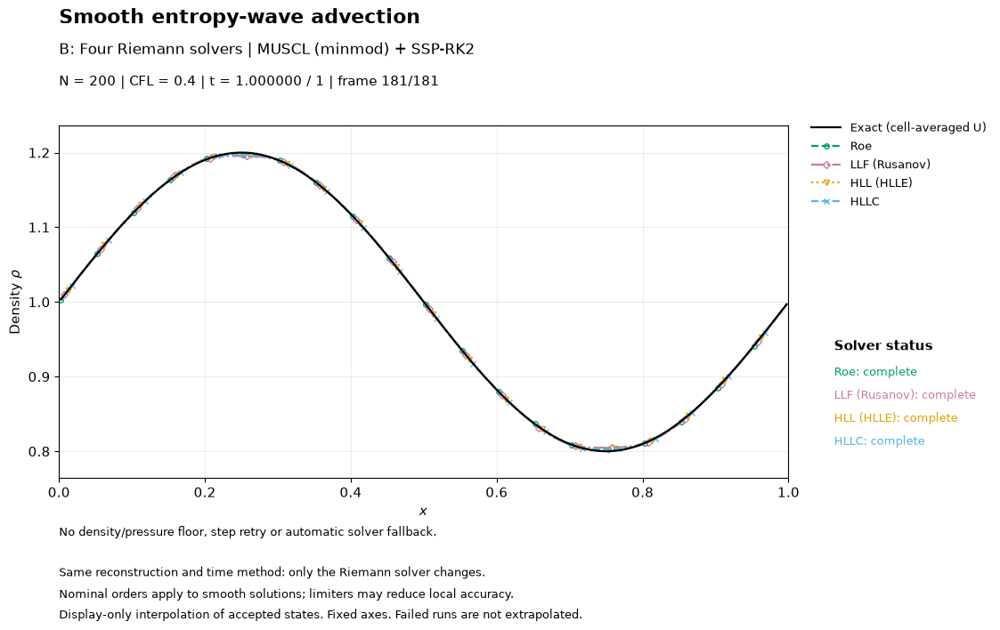

Saved: orders_contact_rho_minmod_four_fluxes.mp4


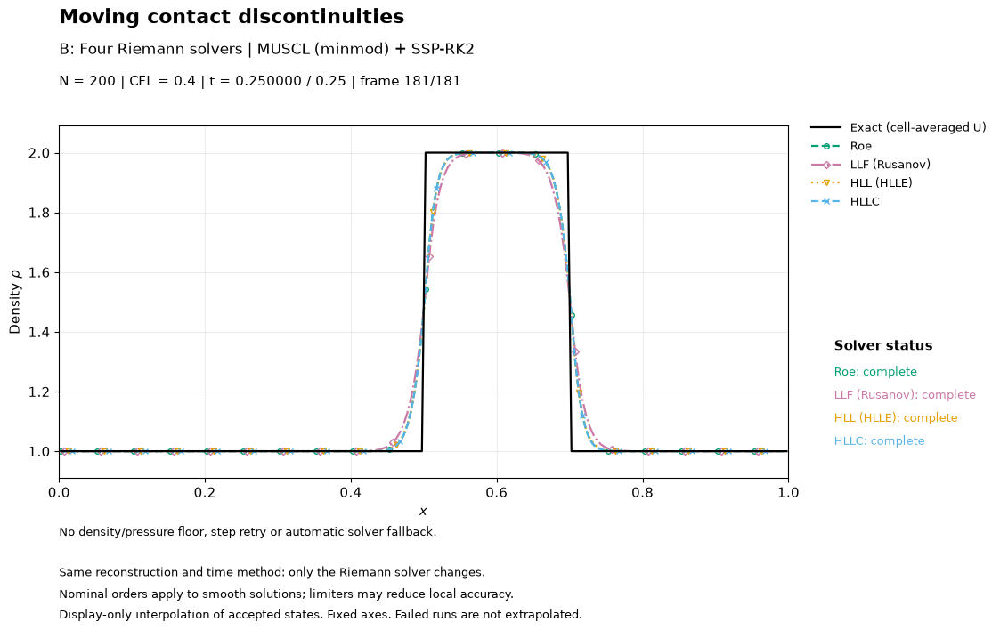

Saved: orders_sod_rho_minmod_four_fluxes.mp4


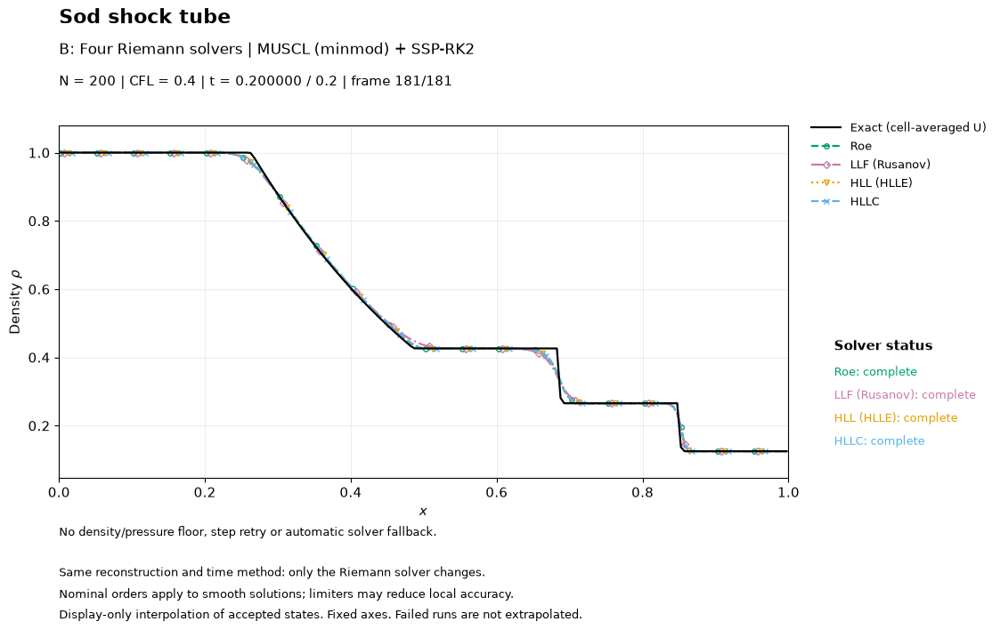

In [27]:
if ORDER_CFG["enabled"] and ORDER_CFG["run_four_flux_comparison"]:
    for key, high in MUSCL_DATA.items():
        for field in ORDER_CFG["fields_by_problem"][key]:
            display(HTML("<h4>B: " + CASE_JA.get(key, PROBLEMS[key].title) + " / " + FIELD_JA[field] + "</h4>"))
            show_order_animation(ORDER_BASE_DATA[key], high, field, ANIM_CFG, ORDER_CFG, mode="muscl")

## C：同じ流束の1次精度と2次精度を比較

各流束に別々の動画を作ります。青い破線は区分一定＋前進Euler、赤橙の実線はMUSCL＋SSP-RK2、黒線は参照解です。同じ色の意味を全動画で維持します。

まず同じ流束の2本を比べ、波面の幅、振幅、振動、停止の有無を確認してください。その後にBへ戻り、高次精度化した4流束の違いを調べます。**Cは空間再構築と時間積分を同時に変更する比較です。** 空間精度だけの影響を分離する実験ではありません。

Saved: orders_entropy_rho_minmod_pair_Roe.mp4


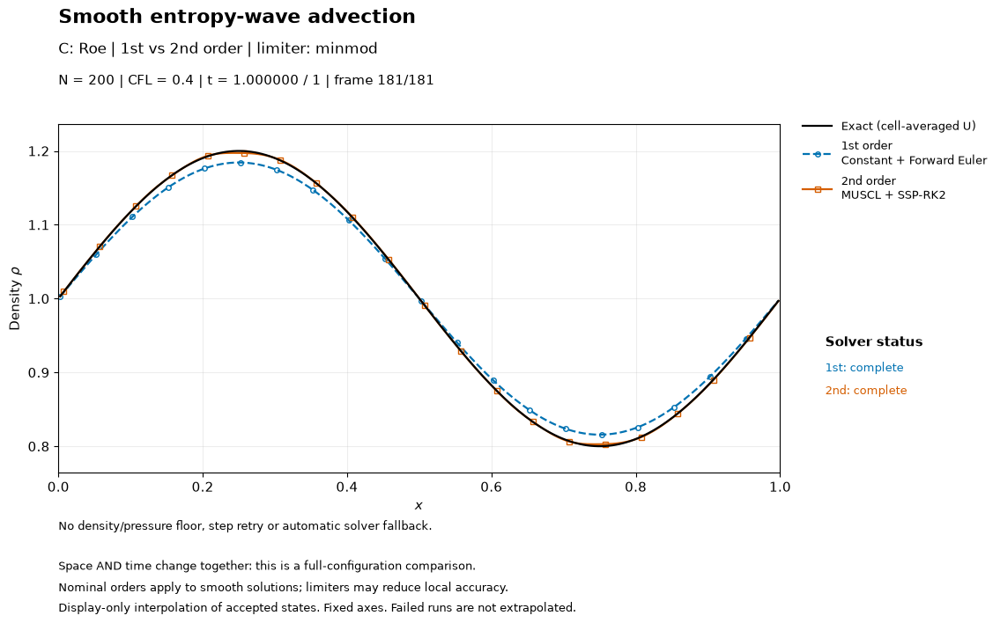

Saved: orders_entropy_rho_minmod_pair_LLF.mp4


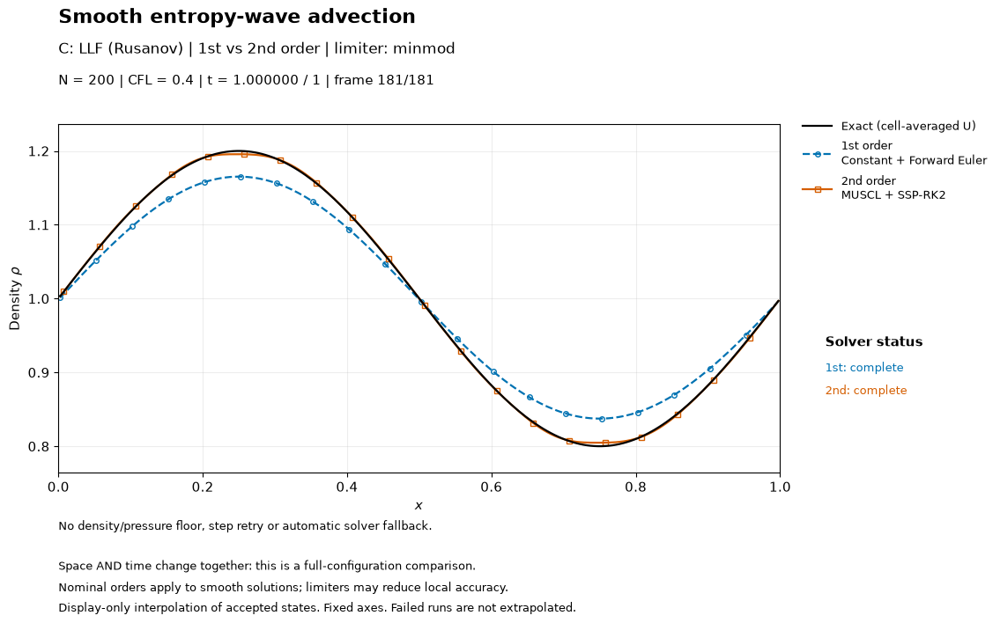

Saved: orders_entropy_rho_minmod_pair_HLL.mp4


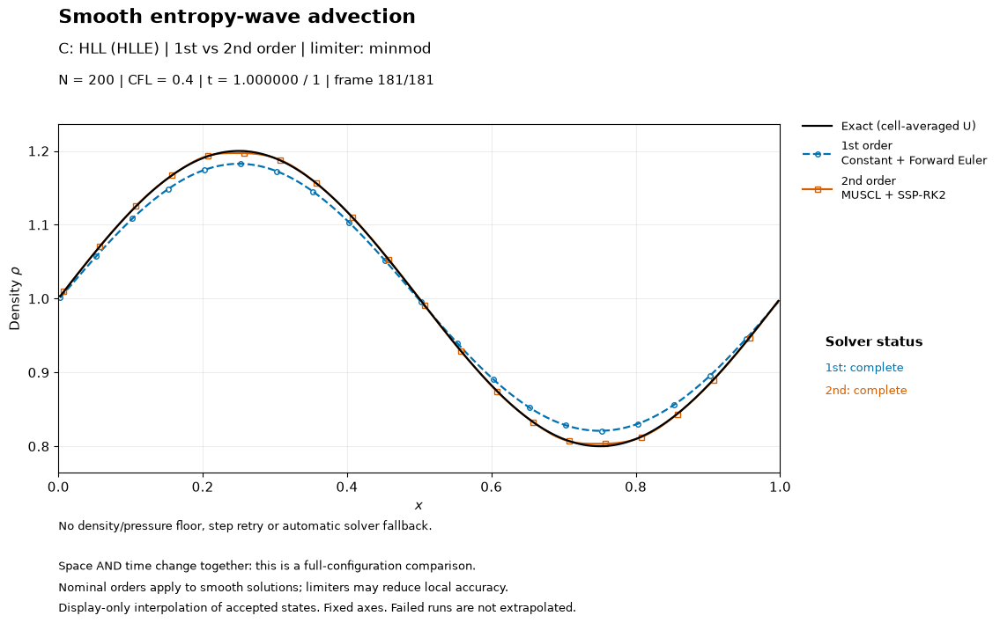

Saved: orders_entropy_rho_minmod_pair_HLLC.mp4


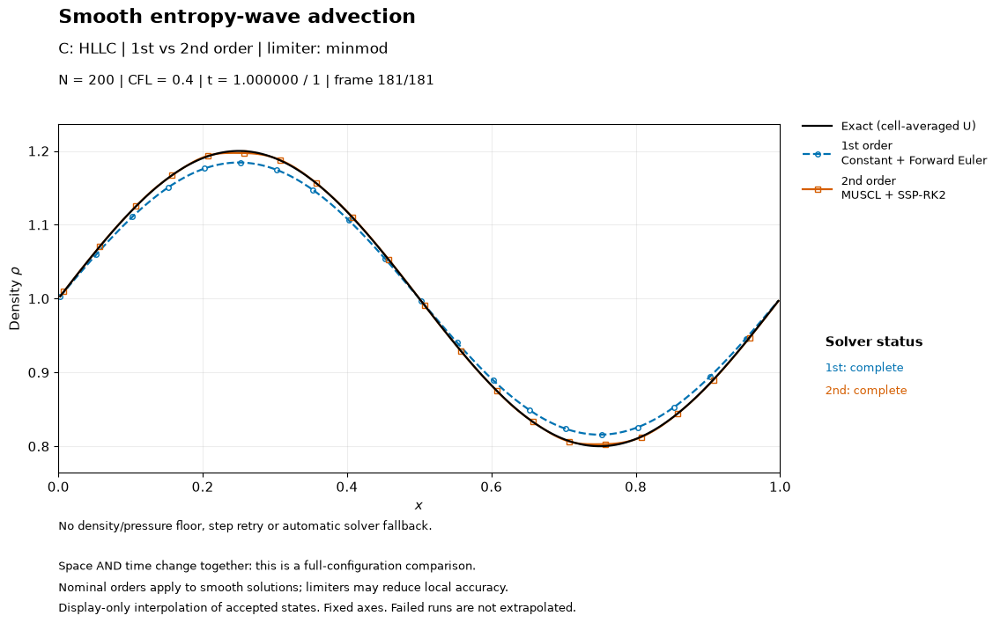

Saved: orders_contact_rho_minmod_pair_Roe.mp4


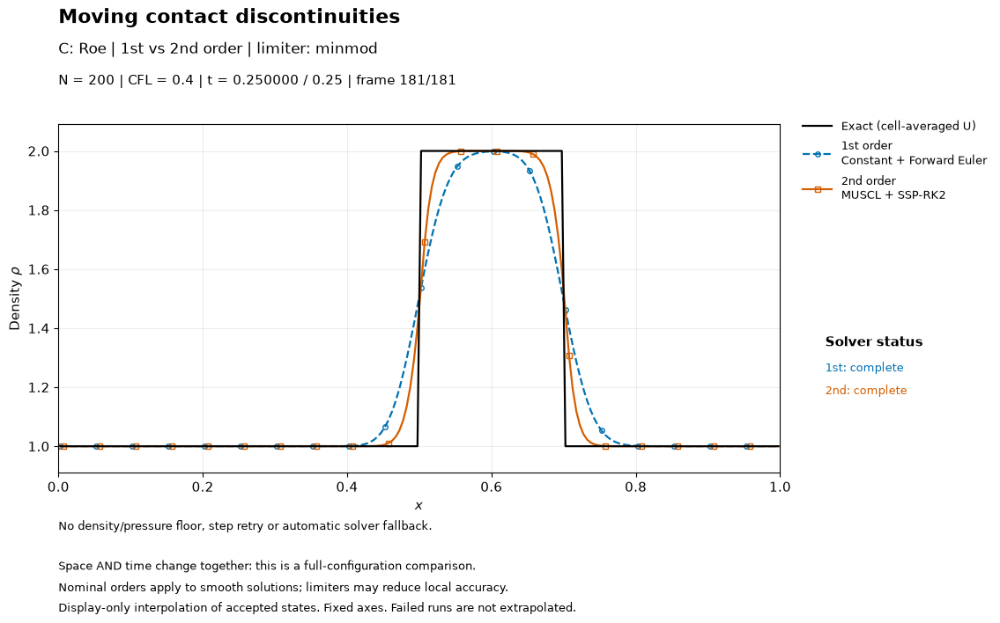

Saved: orders_contact_rho_minmod_pair_LLF.mp4


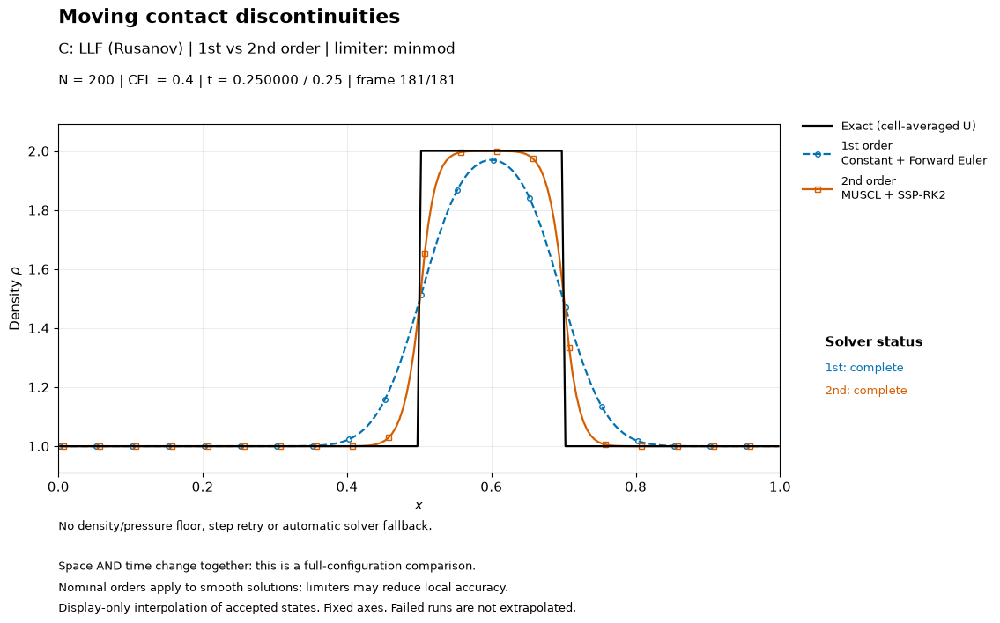

Saved: orders_contact_rho_minmod_pair_HLL.mp4


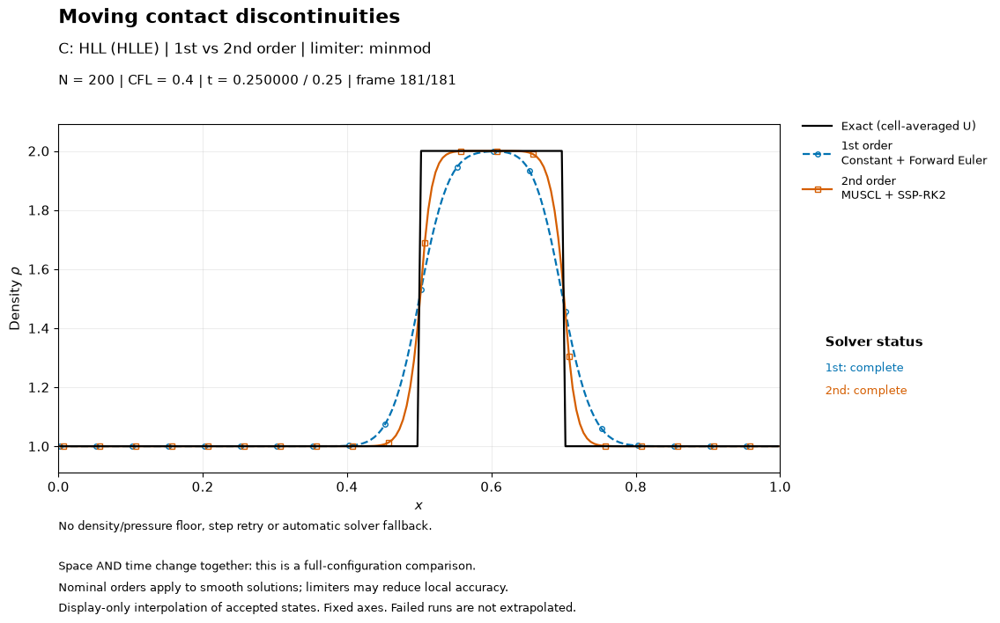

Saved: orders_contact_rho_minmod_pair_HLLC.mp4


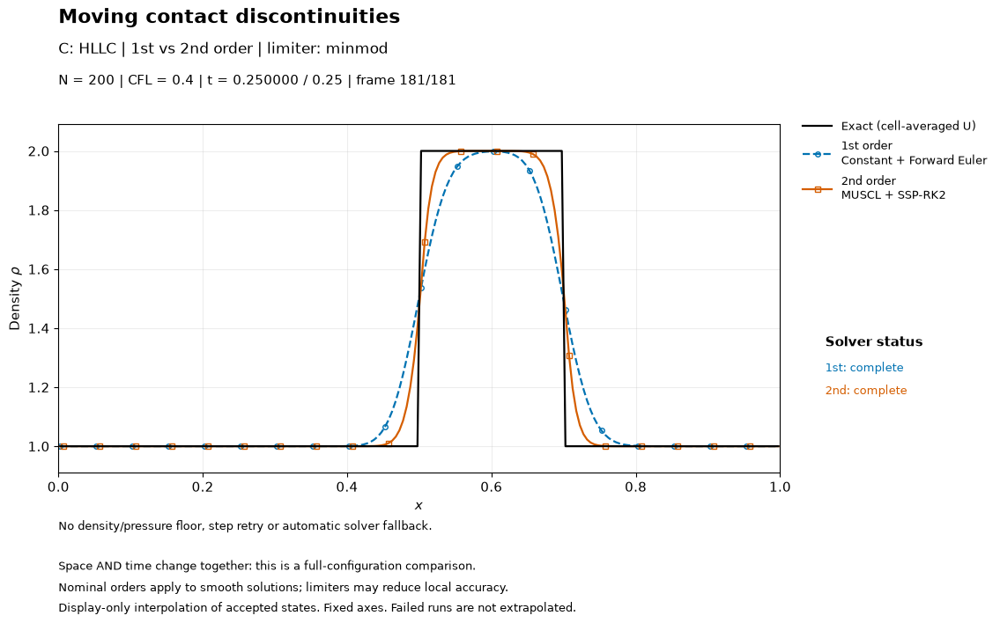

Saved: orders_sod_rho_minmod_pair_Roe.mp4


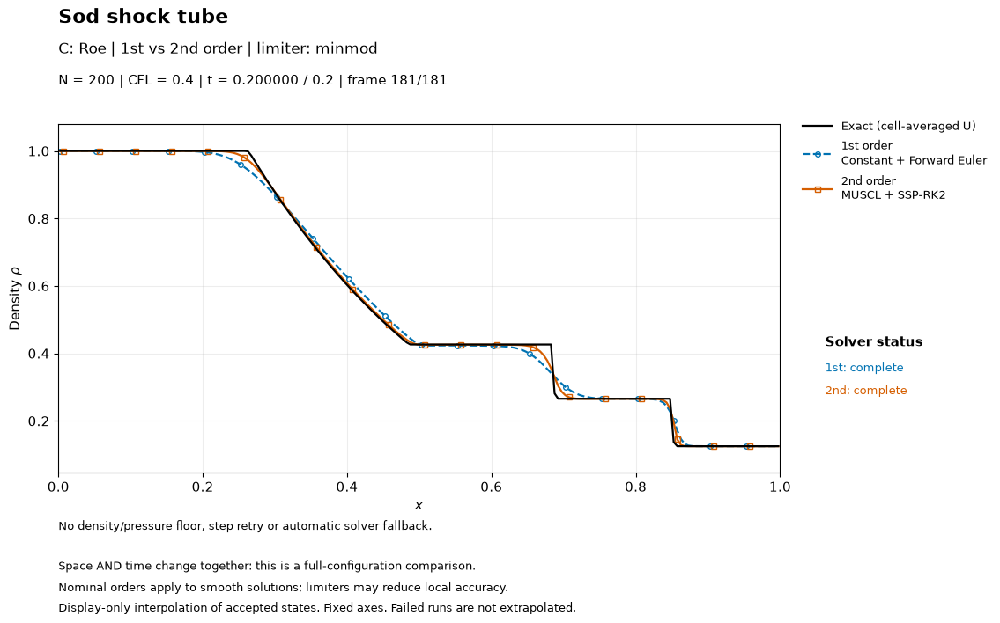

Saved: orders_sod_rho_minmod_pair_LLF.mp4


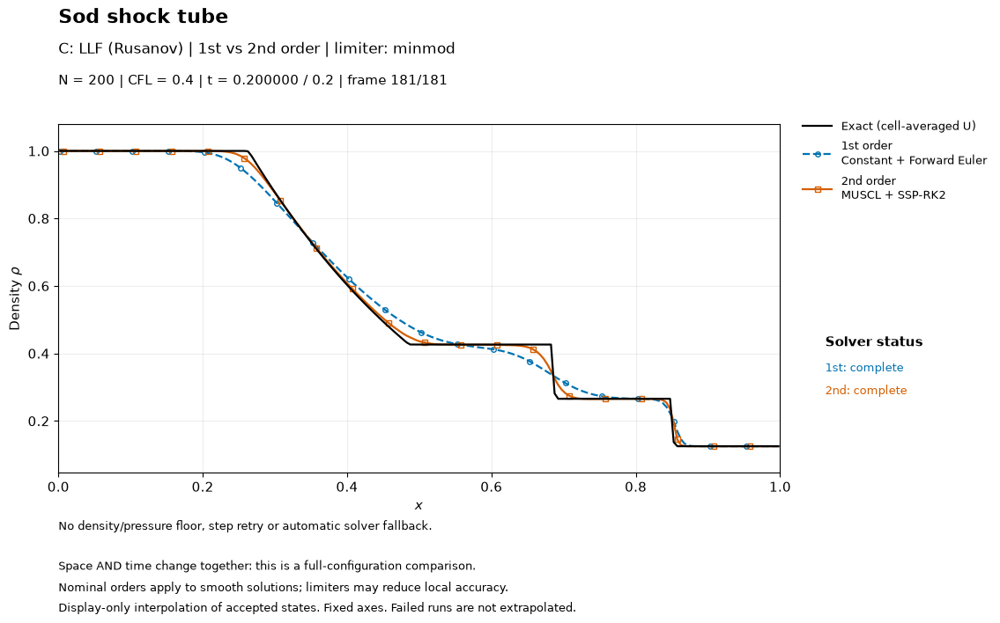

Saved: orders_sod_rho_minmod_pair_HLL.mp4


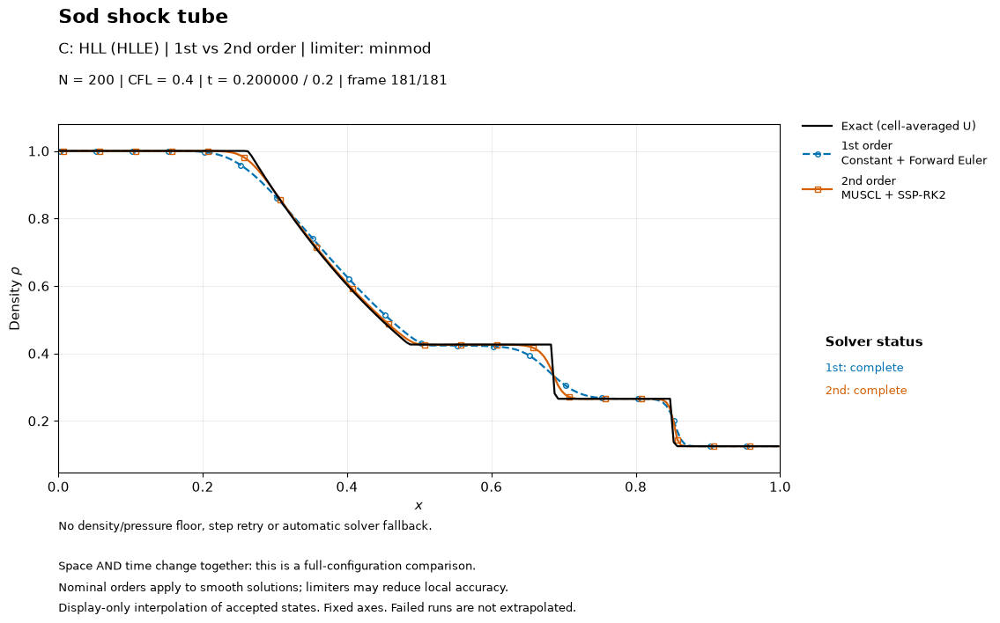

Saved: orders_sod_rho_minmod_pair_HLLC.mp4


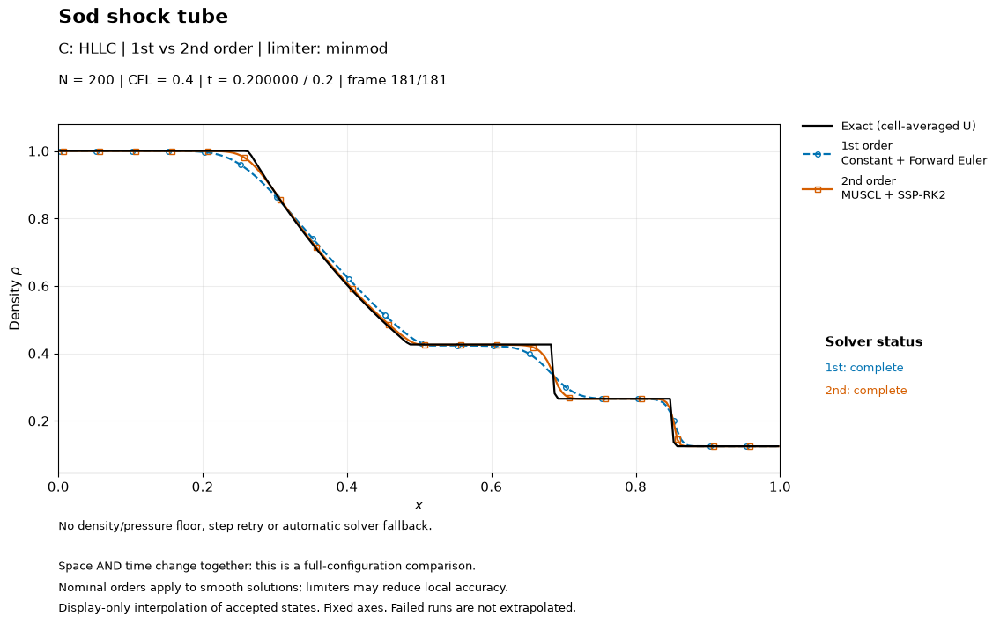

In [28]:
if ORDER_CFG["enabled"] and ORDER_CFG["run_order_pairs"]:
    for key, high in MUSCL_DATA.items():
        for solver in ORDER_CFG["pair_solvers"]:
            for field in ORDER_CFG["fields_by_problem"][key]:
                display(HTML("<h4>C: " + solver_display_name(solver, ANIM_CFG["wave_speeds"]) + " / " + CASE_JA.get(key, PROBLEMS[key].title) + " / " + FIELD_JA[field] + "</h4>"))
                show_order_animation(ORDER_BASE_DATA[key], high, field, ANIM_CFG, ORDER_CFG, mode="pair", solver=solver)

## A・B・Cの動画一覧

MP4を保存した場合、`stage1_orders_gallery.html`にA・B・Cの動画をまとめます。このHTMLは動画を内蔵しているため、Pythonを起動せずに再生できます。ffmpegを使わない場合は、各NotebookセルのJavaScript動画を使用してください。

In [29]:
if ORDER_CFG["enabled"]:
    all_base = dict(ANIMATION_DATA, **ORDER_BASE_DATA)
    ORDER_GALLERY = export_combined_order_gallery(all_base, MUSCL_DATA, ANIM_CFG, ORDER_CFG)
    if ORDER_GALLERY is not None:
        print("Combined gallery:", ORDER_GALLERY)

Saved combined gallery: stage1_orders_gallery.html | 29 videos
Combined gallery: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/stage1_animation_outputs/stage1_orders_gallery.html


## 比較のまとめ

Aは、古典的LF・LWと4流束の基本構成の比較です。LWだけが2次精度なので、すべてを同じ次数に揃えた実験ではありません。BはMUSCLと時間積分を揃えた流束比較、Cは同じ流束での高次精度化の総合比較です。

波形が鋭いこと、全変動が増えないこと、密度・圧力が正であること、厳密解に近いことは、それぞれ別に確認します。図だけで高次精度を証明せず、滑らかな問題の格子収束も併せて調べます。